# Лабораторная работа 6. Группы стран по потребности в помощи

**Цель:** получить группы стран по потребности в поддержке и оценить, можно ли использовать их при планировании трёх пакетов фонда с лимитом **40 стран на каждый пакет в сумме**. Четвёртое решение — рассмотрение выхода из программ.

В пунктах 1–7 используется срез **2023 года: 148 стран**. Строки 2015 года не участвуют в подборе основной модели; в бонусном пункте 8 они обрабатываются с зафиксированными параметрами подготовки 2023 года.

Группы — результат анализа сходства, а не доказательство эффективности вмешательств.

In [1]:
import os
# Ограничиваем потоки для воспроизводимого и быстрого расчёта на небольшом наборе.
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
from pathlib import Path
from io import StringIO
import base64
import zlib
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from IPython.display import display, Markdown
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
import sklearn

SEED = 42
CAPACITY = 40
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 160)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.dpi': 110, 'font.family': 'DejaVu Sans', 'axes.grid': False})

In [2]:
# Загрузка датасета и его проверка
candidates = [Path('lab_6.csv'), Path('upload/lab_6.csv'), Path('/content/lab_6.csv')]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raw = pd.read_csv(StringIO(zlib.decompress(base64.b64decode(EMBEDDED_CSV)).decode('utf-8-sig')))
    print('Использована встроенная копия lab_6.csv.')
else:
    raw = pd.read_csv(data_path)
    print('Прочитан файл:', data_path)

assert raw.shape == (296, 22), 'Ожидалось 296 строк и 22 столбца.'
assert not raw.duplicated(['iso3', 'year']).any(), 'Повтор страны в одном году.'
df = raw.loc[raw['year'].eq(2023)].copy().reset_index(drop=True)
assert len(df) == 148 and df['iso3'].nunique() == 148
assert (df['population'] > 0).all()
print('По годам:', raw.groupby('year').size().to_dict())
print('Рабочий срез:', df.shape, '; полных дублей:', df.duplicated().sum())
display(df.head())

Прочитан файл: lab_6.csv
По годам: {2015: 148, 2023: 148}
Рабочий срез: (148, 22) ; полных дублей: 0


,country,iso3,region,year,population,gdp_per_capita_usd,health_spending_total_musd,doctors_total,nurses_total,hospital_beds_total,life_expectancy_years,infant_mortality_per_1000,under5_mortality_per_1000,maternal_mortality_per_100k,immunization_dtp3_pct,immunization_measles_pct,undernourishment_pct,stunting_under5_pct,access_clean_water_pct,access_sanitation_pct,urban_population_pct,female_literacy_pct
0,Австралия,AUS,Восточная Азия и Океания,2023,26659922,65058.4,180357.3,108932.0,358576.0,NaN,83.1,3.1,3.7,2.0,94.0,91.0,2.5,NaN,100.0,100.0,87.5,NaN
1,Австрия,AUT,Европа и Центральная Азия,2023,9131761,56579.5,57624.1,50362.0,103006.0,61183.0,81.8,2.8,3.3,6.0,87.0,90.0,2.5,NaN,100.0,100.0,69.2,NaN
2,Азербайджан,AZE,Европа и Центральная Азия,2023,10153958,7133.0,3093.5,32340.0,56639.0,37367.0,74.4,13.2,18.7,18.0,51.0,71.0,2.5,6.6,96.8,97.9,58.5,99.7
3,Албания,ALB,Европа и Центральная Азия,2023,2411658,9740.7,1656.7,4532.0,14038.0,6994.0,79.6,8.3,9.4,7.0,97.0,83.0,5.4,NaN,95.1,99.3,58.2,97.2
4,Алжир,DZA,Ближний Восток и Северная Африка,2023,46164219,5370.5,10786.7,76633.0,115780.0,NaN,76.3,19.7,22.0,62.0,92.0,99.0,2.5,9.8,92.4,85.9,74.7,74.2


## 1. Первичный анализ

Сначала проверяем исходные масштабы, допустимые значения и пропуски. Для долей допустим интервал 0–100%, для абсолютных чисел и коэффициентов — неотрицательные значения. Это проверка структуры, а не подтверждение точности источника.

,count,min,25%,50%,75%,max,missing_n,skewness
population,148.0,320409.0,4308990.75,11385239.00,35911068.50,1.438070e+09,0,7.35
gdp_per_capita_usd,145.0,249.8,2066.90,6718.10,23378.60,1.332306e+05,3,2.07
health_spending_total_musd,145.0,48.9,1049.60,3113.40,20425.80,4.642896e+06,3,10.61
doctors_total,144.0,53.0,2526.50,13966.00,48050.50,4.390130e+06,4,9.67
nurses_total,145.0,467.0,8519.00,26365.00,115780.00,5.171663e+06,3,6.26
hospital_beds_total,118.0,526.0,7765.25,18924.50,67597.75,7.942297e+06,30,9.03
life_expectancy_years,148.0,54.5,67.30,74.40,79.00,8.420000e+01,0,-0.36
infant_mortality_per_1000,148.0,1.6,4.65,13.20,33.40,7.190000e+01,0,0.96
under5_mortality_per_1000,148.0,2.1,5.48,15.85,40.38,1.168000e+02,0,1.30
maternal_mortality_per_100k,148.0,1.0,8.00,42.00,186.00,9.930000e+02,0,1.99


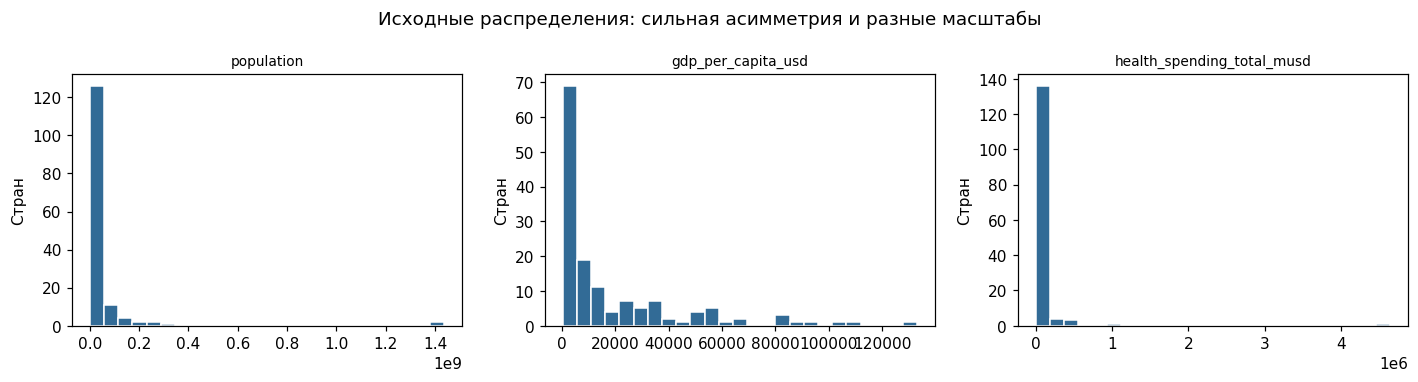

In [3]:
# просмотр данных, по разному распределению
numeric = df.select_dtypes(include='number').drop(columns='year')
scale_table = numeric.describe().T[['count', 'min', '25%', '50%', '75%', 'max']]
scale_table['missing_n'] = numeric.isna().sum()
scale_table['skewness'] = numeric.skew()
display(scale_table.round(2))
pct_cols = [c for c in numeric if c.endswith('_pct')]
assert all(df[c].dropna().between(0, 100).all() for c in pct_cols)
assert (numeric.drop(columns=pct_cols).min() >= 0).all()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ['population', 'gdp_per_capita_usd', 'health_spending_total_musd']):
    ax.hist(df[col].dropna(), bins=25, color='#326b96', edgecolor='white')
    ax.set_title(col, fontsize=9)
    ax.set_ylabel('Стран')
fig.suptitle('Исходные распределения: сильная асимметрия и разные масштабы')
plt.tight_layout()
plt.show()

### Единицы и роль каждого столбца

| Столбец | Рабочие единицы / решение |
|---|---|
| country, iso3 | Название и ключ; не признаки расстояния |
| region | Только описание и проверка состава; не кодируем как числовой признак |
| year | Только отбор 2023 года |
| population | Знаменатель для пересчёта; размер страны учитывается при планировании объёма помощи, но не определяет кластер потребности |
| gdp_per_capita_usd | USD/жителя, затем log1p; блок «Экономика» |
| health_spending_total_musd | ×1 000 000 / население → USD/жителя; оставляем для описания, исключаем из расстояния из-за близости к ВВП |
| doctors_total, nurses_total, hospital_beds_total | / население ×1 000 → на 1 000 жителей; затем log1p, общий блок «Медресурсы» |
| life_expectancy_years | Годы; блок «Исходы», направление обращаем: меньше лет — больше потребность |
| infant_mortality_per_1000 | На 1 000 живорождений; описание, исключаем как почти дубль смертности до 5 лет |
| under5_mortality_per_1000 | На 1 000 живорождений, log1p; блок «Исходы» |
| maternal_mortality_per_100k | На 100 000 живорождений, log1p; блок «Исходы»; не делим на население страны |
| immunization_dtp3_pct, immunization_measles_pct | % соответствующей детской популяции; общий блок «Вакцинация», обращаем направление |
| undernourishment_pct, stunting_under5_pct | % населения / % детей до 5 лет соответственно; общий блок «Питание». Это разные явления, оба сохраняем |
| access_clean_water_pct, access_sanitation_pct | % населения; общий блок «Инфраструктура», обращаем направление |
| urban_population_pct | % населения; контекст и вспомогательный признак заполнения, исключаем из кластеризации: урбанизация сама по себе не мера нуждаемости |
| female_literacy_pct | % соответствующей женской популяции; блок «Грамотность», обращаем направление |

USD не превращаем в сопоставимую покупательную способность: данных PPP и цен нет. Поэтому расходы в USD не трактуем как качество лечения и не даём им отдельного веса. Пересчёт итогов на население среза тоже приблизителен, если исходный показатель измерен в другом году.

,country,population,health_usd_per_capita,doctors_per_1000,nurses_per_1000,beds_per_1000
31,Гватемала,18124838,391.44,1.28,2.27,0.45
43,Индия,1438069596,81.30,0.72,1.72,1.59
58,Китай,1410710000,769.80,3.11,3.67,5.63
103,США,336755052,13787.16,3.68,13.38,2.68


,Признак 1,Признак 2,Spearman,Пар наблюдений
31,infant_mortality_per_1000,under5_mortality_per_1000,0.995,148
12,gdp_per_capita_usd,health_usd_per_capita,0.971,145
17,life_expectancy_years,under5_mortality_per_1000,-0.937,148
16,life_expectancy_years,infant_mortality_per_1000,-0.934,148
45,under5_mortality_per_1000,maternal_mortality_per_100k,0.919,148
32,infant_mortality_per_1000,maternal_mortality_per_100k,0.918,148
54,under5_mortality_per_1000,health_usd_per_capita,-0.907,145
0,gdp_per_capita_usd,life_expectancy_years,0.906,145
18,life_expectancy_years,maternal_mortality_per_100k,-0.905,148
27,life_expectancy_years,health_usd_per_capita,0.903,145


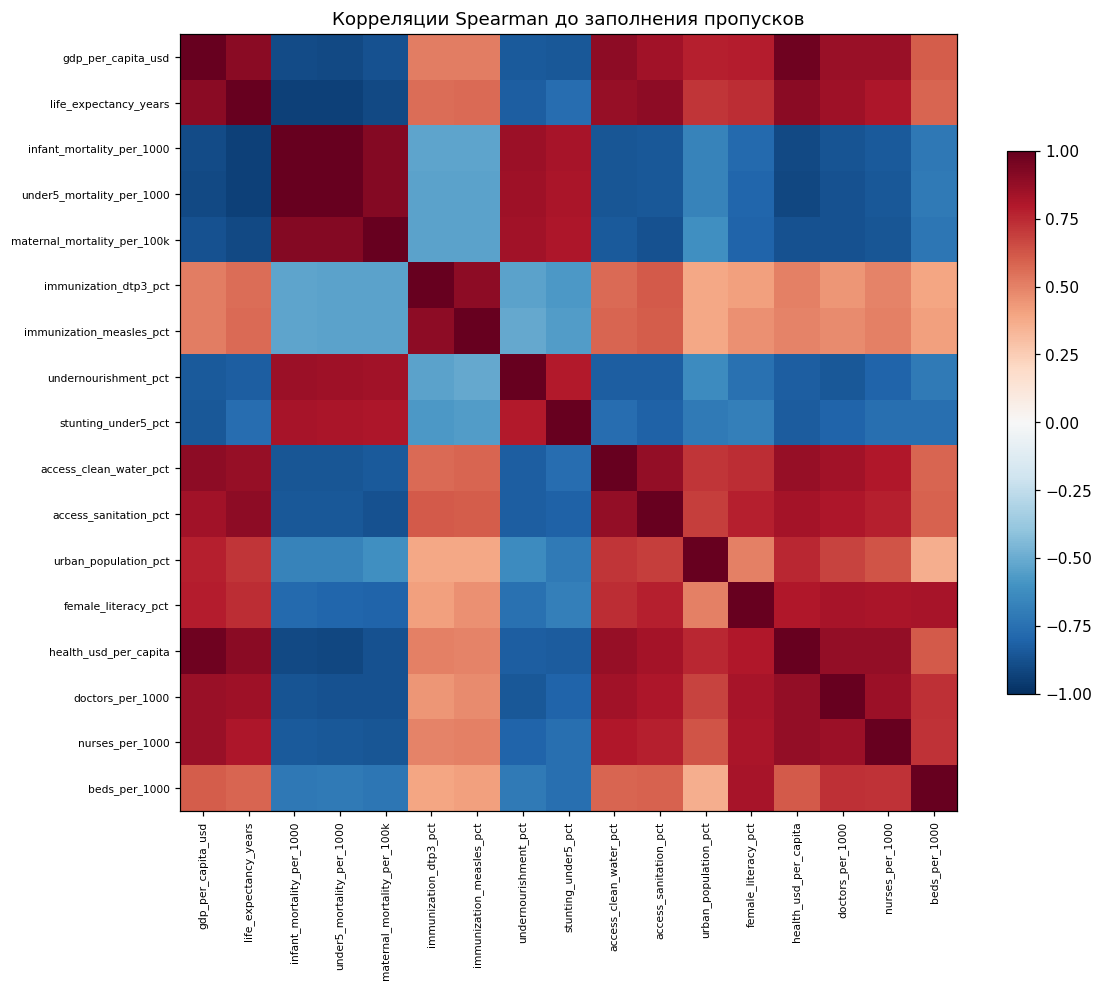

In [4]:
# Одна функция пересчёта единиц применяется к любому году.
def comparable_units(frame):
    result = frame.drop(columns=['country', 'iso3', 'region', 'year', 'population']).copy()
    result['health_usd_per_capita'] = result.pop('health_spending_total_musd') * 1_000_000 / frame['population']
    for total, rate in [('doctors_total', 'doctors_per_1000'),
                        ('nurses_total', 'nurses_per_1000'),
                        ('hospital_beds_total', 'beds_per_1000')]:
        result[rate] = result.pop(total) / frame['population'] * 1_000
    return result

R = comparable_units(df)

display(pd.concat([df[['country', 'population']], R[['health_usd_per_capita', 'doctors_per_1000',
        'nurses_per_1000', 'beds_per_1000']]], axis=1).loc[df['iso3'].isin(['IND', 'GTM', 'CHN', 'USA'])].round(2))
# тепловая карта корреляций
# Spearman сравнивает ранги и менее чувствителен к денежным выбросам.
# Корреляции считаются по наблюдаемым парам, до заполнения пропусков.
corr = R.corr(method='spearman')
pairs = []
for i, a in enumerate(corr.columns):
    for b in corr.columns[i + 1:]:
        pairs.append((a, b, corr.loc[a, b], R[[a, b]].dropna().shape[0]))
pairs = pd.DataFrame(pairs, columns=['Признак 1', 'Признак 2', 'Spearman', 'Пар наблюдений'])
display(pairs.loc[pairs['Spearman'].abs().ge(.85)].sort_values('Spearman', key=abs, ascending=False).round(3))
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
ax.set_title('Корреляции Spearman до заполнения пропусков')
fig.colorbar(im, ax=ax, shrink=.7)
plt.tight_layout()
plt.show()

,n,%
stunting_under5_pct,57,38.5
female_literacy_pct,54,36.5
beds_per_1000,30,20.3
undernourishment_pct,13,8.8
access_sanitation_pct,5,3.4
access_clean_water_pct,4,2.7
doctors_per_1000,4,2.7
gdp_per_capita_usd,3,2.0
health_usd_per_capita,3,2.0
nurses_per_1000,3,2.0


Границы терцилей наблюдаемого ВВП: {0.3333333333333333: 2885.5, 0.6666666666666666: 13830.8}


,stunting_under5_pct,female_literacy_pct,beds_per_1000
gdp_per_capita_usd,,,
Нижняя треть,12.5,16.7,41.7
Средняя треть,33.3,14.6,16.7
Верхняя треть,67.3,75.5,2.0


Отдельно стран без ВВП: ['Йемен', 'Эритрея', 'Южный Судан']


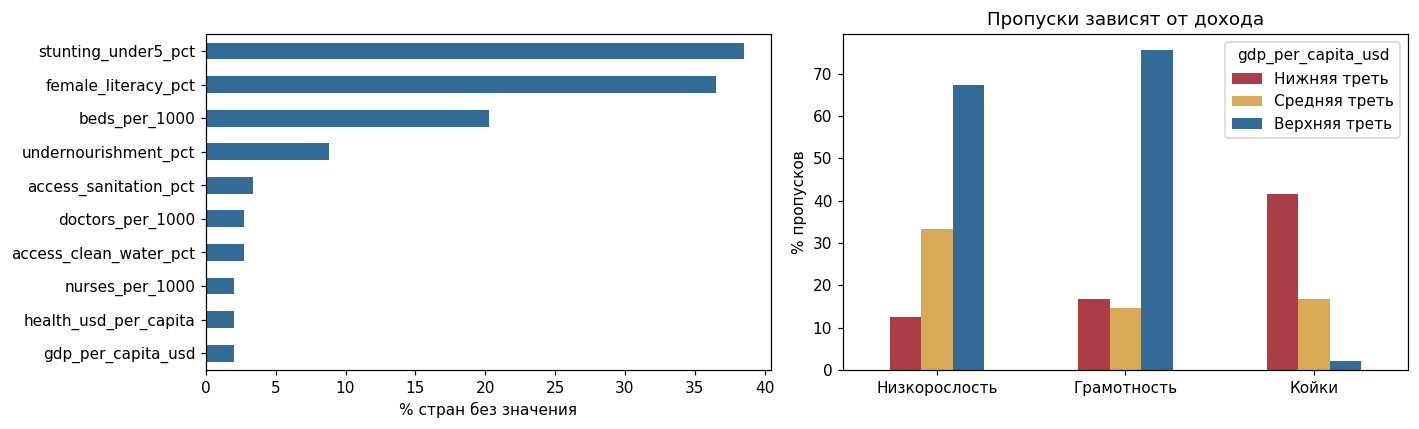

In [5]:
missing = pd.DataFrame({'n': R.isna().sum(), '%': R.isna().mean() * 100})
display(missing.loc[missing['n'].gt(0)].sort_values('%', ascending=False).round(1))
# Терцили — относительные группы именно этого набора, не категории дохода Всемирного банка.
income_observed = pd.qcut(R['gdp_per_capita_usd'], 3, labels=['Нижняя треть', 'Средняя треть', 'Верхняя треть'])
focus_missing = ['stunting_under5_pct', 'female_literacy_pct', 'beds_per_1000']
missing_by_income = R[focus_missing].isna().groupby(income_observed, observed=True).mean() * 100
print('Границы терцилей наблюдаемого ВВП:', R['gdp_per_capita_usd'].quantile([1/3, 2/3]).round(1).to_dict())
display(missing_by_income.round(1))
print('Отдельно стран без ВВП:', df.loc[R['gdp_per_capita_usd'].isna(), 'country'].tolist())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
missing.loc[missing.n.gt(0), '%'].sort_values().plot.barh(ax=axes[0], color='#326b96')
axes[0].set_xlabel('% стран без значения')
missing_by_income.T.plot.bar(ax=axes[1], rot=0, color=['#ac3c45', '#d9aa55', '#326b96'])
axes[1].set_ylabel('% пропусков'); axes[1].set_title('Пропуски зависят от дохода')
axes[1].set_xticklabels(['Низкорослость', 'Грамотность', 'Койки'])
plt.tight_layout(); plt.show()

**Вывод по первичному анализу.** Масштабы различаются на порядки, исходные итоги отражают численность населения. Смертность младенцев и детей до 5 лет почти дублирует одну характеристику, ВВП и расходы на жителя очень близки. В исходах, вакцинации и инфраструктуре тоже есть сильные связи.

Таблица пропусков подтверждает механизм из задания: отсутствие обследований питания/грамотности чаще связано с благополучием, отсутствие данных о койках — с низким доходом. Пропуск не заменяем нулём и не считаем всегда признаком кризиса. Пропуски ВВП анализируются отдельно; они не входят в таблицу терцилей до заполнения.

## 2. Подготовка данных

**Условное заполнение, без 2015 года:**

1. Строим пространство полностью наблюдаемых вспомогательных показателей: продолжительность жизни, логарифмы смертности, две вакцинации и урбанизация; стандартизируем их.
2. Пропущенный log1p(ВВП) восстанавливаем взвешенным средним 7 ближайших наблюдаемых стран. Добавляем восстановленный log1p(ВВП) в пространство поиска.
3. Для остальных пропусков ищем доноров в той же трети распределения ВВП. При числе доноров менее 5 расширяем поиск на все наблюдаемые страны. Берём до 7 ближайших; веса равны `1 / (расстояние + 0.1)`.
4. Денежные показатели и медицинские ресурсы заполняем в логарифмическом пространстве; доли — в исходных процентах. Существующие значения не меняем. Пропущенные богатые страны получают оценки по сходным богатым странам, бедные — по сходным бедным.

Это допущение о сопоставимости стран, не восстановление «истины»: MNAR-пропуски по одному срезу однозначно не идентифицируются. Низкая смертность не гарантирует низкую низкорослость. Поэтому ниже отдельно проверяется чувствительность к числу соседей, способу заполнения, исключению наиболее неполных показателей и случайному выбору доноров. Индикаторы отсутствия значений сохраняем для контроля, но не включаем в расстояния: иначе рискуем получить группы систем отчётности.

In [6]:
# Выбор показателей и категорий
ANCHORS = ['life_expectancy_years', 'under5_mortality_per_1000',
           'maternal_mortality_per_100k', 'immunization_dtp3_pct',
           'immunization_measles_pct', 'urban_population_pct']
LOG_IMPUTE = ['gdp_per_capita_usd', 'health_usd_per_capita',
              'doctors_per_1000', 'nurses_per_1000', 'beds_per_1000']

def neighbor_fill(s, A, n_neighbors=7, strata=None, rng=None):
    out = s.copy()
    observed = s.notna().to_numpy()
    for i in np.flatnonzero(~observed):
        donors = np.flatnonzero(observed if strata is None else observed & (strata == strata[i]))
        if len(donors) < 5:
            donors = np.flatnonzero(observed)
        distance = np.linalg.norm(A[donors] - A[i], axis=1)
        closest = np.argsort(distance)[:n_neighbors]
        donors, distance = donors[closest], distance[closest]
        weights = 1 / (distance + .1)
        if rng is None:
            out.iloc[i] = np.average(s.iloc[donors], weights=weights)
        else:
            # Донорные реализации — проверка чувствительности, не апостериорные вероятности.
            chosen = rng.choice(donors, p=weights / weights.sum())
            out.iloc[i] = s.iloc[chosen]
    return out

def impute_data(source, n_neighbors=7, use_strata=True, mode='neighbors', rng=None,
                parameters=None, return_parameters=False):
    result = source.copy()
    if mode == 'median':
        # Только контрольный сценарий; основным решением общая медиана не является.
        for col in result:
            v = np.log1p(result[col]) if col in LOG_IMPUTE else result[col]
            v = v.fillna(v.median())
            result[col] = np.expm1(v) if col in LOG_IMPUTE else v
        return result
    anchor = source[ANCHORS].copy()
    for col in ['under5_mortality_per_1000', 'maternal_mortality_per_100k']:
        anchor[col] = np.log1p(anchor[col])
    assert not anchor.isna().any().any()
    # Параметры можно сохранить и затем применять к другому году без повторного fit.
    if parameters is None:
        anchor_scaler = StandardScaler().fit(anchor)
    else:
        anchor_scaler = parameters['anchor_scaler']
    A = anchor_scaler.transform(anchor)
    log_gdp = neighbor_fill(np.log1p(source['gdp_per_capita_usd']), A, n_neighbors, rng=rng)
    # Меняем только пропущенные значения, чтобы сохранить наблюдаемое число буквально.
    result['gdp_per_capita_usd'] = source['gdp_per_capita_usd'].fillna(np.expm1(log_gdp))
    if parameters is None:
        gdp_scaler = StandardScaler().fit(log_gdp.to_numpy().reshape(-1, 1))
        income_cuts = result['gdp_per_capita_usd'].quantile([1/3, 2/3]).to_numpy()
        parameters = {'anchor_scaler': anchor_scaler, 'gdp_scaler': gdp_scaler,
                      'income_cuts': income_cuts}
    else:
        gdp_scaler = parameters['gdp_scaler']
    A = np.column_stack([A, gdp_scaler.transform(log_gdp.to_numpy().reshape(-1, 1))])
    strata = np.searchsorted(parameters['income_cuts'], result['gdp_per_capita_usd'], side='left') if use_strata else None
    for col in source.columns:
        if col == 'gdp_per_capita_usd' or not source[col].isna().any():
            continue
        v = np.log1p(source[col]) if col in LOG_IMPUTE else source[col]
        filled = neighbor_fill(v, A, n_neighbors, strata, rng)
        estimate = np.expm1(filled) if col in LOG_IMPUTE else filled
        result[col] = source[col].fillna(estimate)
    return (result, parameters) if return_parameters else result

filled, imputation_parameters = impute_data(R, return_parameters=True)
missing_flags = R.isna().add_suffix('__missing')
assert np.isfinite(filled.to_numpy()).all()
assert np.allclose(filled.to_numpy()[R.notna().to_numpy()], R.to_numpy()[R.notna().to_numpy()])
print('Осталось пропусков:', int(filled.isna().sum().sum()))
imputation_audit = []
for col in R.columns[R.isna().any()]:
    m = R[col].isna()
    imputation_audit.append([col, m.sum(), R[col].median(), filled.loc[m, col].min(),
                            filled.loc[m, col].median(), filled.loc[m, col].max()])
display(pd.DataFrame(imputation_audit, columns=['Показатель', 'Заполнено', 'Медиана наблюдений',
        'Минимум оценок', 'Медиана оценок', 'Максимум оценок']).round(2))
example_mask = df['iso3'].isin(['AUS', 'DEU', 'IND', 'GTM', 'BDI', 'SSD', 'YEM'])
display(pd.concat([df[['country']], filled[['gdp_per_capita_usd'] + focus_missing],
        missing_flags[[c + '__missing' for c in focus_missing]]], axis=1).loc[example_mask].round(2))

Осталось пропусков: 0


,Показатель,Заполнено,Медиана наблюдений,Минимум оценок,Медиана оценок,Максимум оценок
0,gdp_per_capita_usd,3,6718.10,853.45,881.40,1371.50
1,undernourishment_pct,13,5.20,2.50,7.34,27.59
2,stunting_under5_pct,57,17.60,1.46,3.40,38.64
3,access_clean_water_pct,4,95.40,71.77,87.86,98.87
4,access_sanitation_pct,5,90.60,57.05,85.46,94.90
5,female_literacy_pct,54,88.25,40.16,97.61,98.24
6,health_usd_per_capita,3,375.82,34.74,43.64,54.78
7,doctors_per_1000,4,1.62,0.21,0.74,3.76
8,nurses_per_1000,3,3.35,0.74,2.79,2.79
9,beds_per_1000,30,2.41,0.42,0.81,2.96


,country,gdp_per_capita_usd,stunting_under5_pct,female_literacy_pct,beds_per_1000,stunting_under5_pct__missing,female_literacy_pct__missing,beds_per_1000__missing
0,Австралия,65058.40,2.76,97.83,2.72,True,True,True
20,Бурунди,249.80,58.00,66.10,0.52,False,False,True
31,Гватемала,5754.40,46.00,78.70,0.45,False,False,False
34,Германия,54776.80,2.79,97.98,7.55,True,True,False
43,Индия,2434.40,35.50,74.90,1.59,False,False,False
50,Йемен,853.45,48.50,54.10,0.46,False,False,False
145,Южный Судан,881.40,33.67,40.16,0.42,True,True,True


### Близкие признаки и масштабирование

Оставляем **7 тематических осей**, а не даём каждой колонке отдельный голос: экономика (1), исходы (3), вакцинация (2), питание (2), инфраструктура (2), медицинские ресурсы (3), грамотность (1). Внутри блока сначала стандартизируем преобразованные показатели, затем усредняем. Полученные блоки снова стандартизируем: каждый имеет единичную дисперсию и равный исходный вес.

Все оси направлены одинаково: **больше значение → больше потребность**. Суммирование стандартизованных признаков с одинаковым направлением уменьшает двойной счёт, но не делает блоки независимыми. Между блоками остаётся общая ось развития; PCA её выявит. Равные веса блоков — прозрачный выбор аналитика, а не выученные показатели эффективности фонда.

Log1p уменьшает влияние очень больших ресурсов и смертности, сохраняя порядок стран. Проценты оставляем без logit: в данных есть 100%, а произвольная коррекция краёв создала бы дополнительные допущения. Выбросы не удаляем: крайняя нуждаемость важна фонду.

,count,mean,std,min,25%,50%,75%,max
Экономика,148.0,-0.0,1.003,-1.991,-0.847,0.059,0.822,2.132
Исходы,148.0,0.0,1.003,-1.623,-0.964,-0.044,0.905,2.113
Вакцинация,148.0,0.0,1.003,-1.028,-0.772,-0.396,0.564,3.357
Питание,148.0,0.0,1.003,-1.039,-0.921,-0.300,0.698,2.853
Инфраструктура,148.0,0.0,1.003,-0.838,-0.795,-0.529,0.735,2.837
Медресурсы,148.0,-0.0,1.003,-1.796,-0.933,0.094,0.957,1.726
Грамотность,148.0,0.0,1.003,-0.866,-0.757,-0.538,0.700,2.947


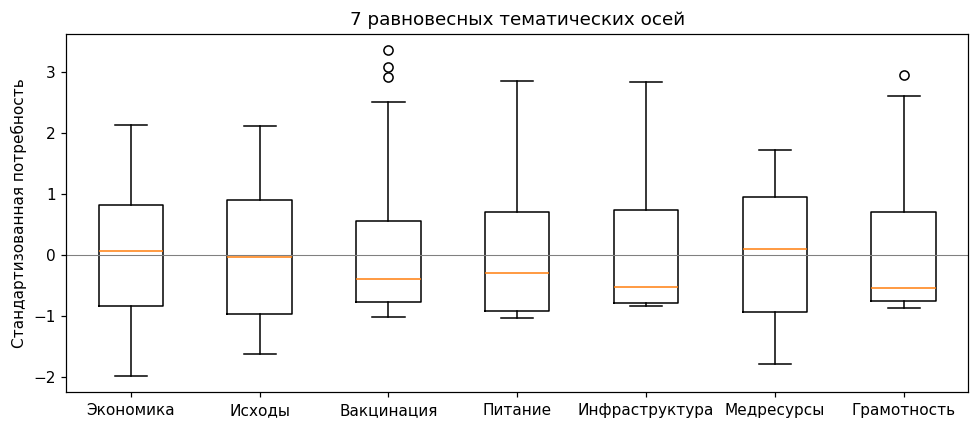

In [7]:
# Просто визуал, тут практически ничего не считается
BLOCKS = {
    'Экономика': ['gdp_per_capita_usd'],
    'Исходы': ['life_expectancy_years', 'under5_mortality_per_1000', 'maternal_mortality_per_100k'],
    'Вакцинация': ['immunization_dtp3_pct', 'immunization_measles_pct'],
    'Питание': ['undernourishment_pct', 'stunting_under5_pct'],
    'Инфраструктура': ['access_clean_water_pct', 'access_sanitation_pct'],
    'Медресурсы': ['doctors_per_1000', 'nurses_per_1000', 'beds_per_1000'],
    'Грамотность': ['female_literacy_pct'],
}
HIGH_NEED = ['under5_mortality_per_1000', 'maternal_mortality_per_100k',
             'undernourishment_pct', 'stunting_under5_pct']
LOG_FEATURES = ['gdp_per_capita_usd', 'under5_mortality_per_1000', 'maternal_mortality_per_100k',
                'doctors_per_1000', 'nurses_per_1000', 'beds_per_1000']

# Только эти две функции грубо говоря интерпретируют данные для дальнейшей визализации
def transform_input_features(data, drop=()):
    blocks = {b: [c for c in cols if c not in drop] for b, cols in BLOCKS.items()}
    blocks = {b: cols for b, cols in blocks.items() if cols}
    transformed = data[[c for cols in blocks.values() for c in cols]].copy()
    for col in transformed:
        if col in LOG_FEATURES:
            transformed[col] = np.log1p(transformed[col])
        if col not in HIGH_NEED:
            transformed[col] = -transformed[col]
    return blocks, transformed

def make_features(data, drop=()):
    blocks, transformed = transform_input_features(data, drop)
    feature_scaler = StandardScaler()
    standardized = pd.DataFrame(feature_scaler.fit_transform(transformed), columns=transformed.columns)
    block_means = pd.DataFrame({b: standardized[cols].mean(axis=1) for b, cols in blocks.items()})
    block_scaler = StandardScaler()
    X = pd.DataFrame(block_scaler.fit_transform(block_means), columns=block_means.columns)
    return X, feature_scaler, block_scaler

X, feature_scaler, block_scaler = make_features(filled)
assert X.shape == (148, 7)
assert np.allclose(X.mean(), 0, atol=1e-10)
assert np.allclose(X.std(ddof=0), 1)
display(X.describe().T.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(X.to_numpy())
ax.set_xticks(np.arange(1, X.shape[1] + 1), X.columns)
ax.axhline(0, color='grey', lw=.7)
ax.set_ylabel('Стандартизованная потребность'); ax.set_title('7 равновесных тематических осей')
plt.tight_layout(); plt.show()

## 3. PCA

PCA вычисляется для семи тематических осей. Выбираем **минимальное число компонент, сохраняющее не менее 90% дисперсии**, заранее заданный критерий. Это доля разброса подготовленных признаков, а не точность рекомендаций. Для k-means используем эти компоненты с их исходными дисперсиями, **без whitening и без повторной стандартизации компонент**: иначе небольшие компоненты получили бы чрезмерный вес.

,Компонента,"Дисперсия, %","Накопленная, %"
0,1,79.14,79.14
1,2,8.83,87.97
2,3,4.03,92.00
3,4,3.22,95.22
4,5,2.05,97.27
5,6,1.72,99.00
6,7,1.00,100.00


Для кластеризации используем компонент: 3


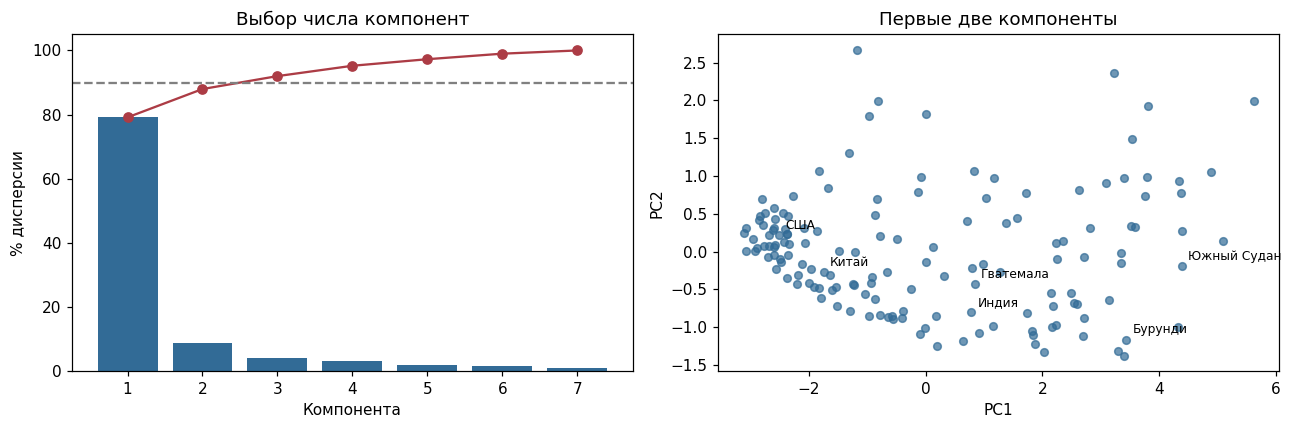

,PC1: коэффициент,PC2: коэффициент,"corr(block, PC1)","corr(block, PC2)"
Экономика,0.393,-0.211,0.925,-0.166
Исходы,0.406,-0.164,0.955,-0.129
Вакцинация,0.285,0.937,0.670,0.737
Питание,0.393,-0.000,0.926,-0.000
Инфраструктура,0.389,0.001,0.916,0.001
Медресурсы,0.393,-0.199,0.925,-0.157
Грамотность,0.373,-0.106,0.878,-0.083


**Результат:** PC1 объясняет 79.14%, PC2 — 8.83%; вместе 87.97%. 3 компоненты сохраняют 92.00%.

In [8]:
pca = PCA().fit(X)
# Знак компоненты произволен. Фиксируем PC1 к росту общей нуждаемости, PC2 к дефициту вакцинации.
if pca.components_[0].sum() < 0:
    pca.components_[0] *= -1
if pca.components_[1, X.columns.get_loc('Вакцинация')] < 0:
    pca.components_[1] *= -1
scores_all = pca.transform(X)
cumulative = pca.explained_variance_ratio_.cumsum()
n_components = int(np.searchsorted(cumulative, .90) + 1)
Y = scores_all[:, :n_components]
variance = pd.DataFrame({'Компонента': np.arange(1, len(cumulative)+1),
                        'Дисперсия, %': pca.explained_variance_ratio_ * 100,
                        'Накопленная, %': cumulative * 100})
display(variance.round(2))
print('Для кластеризации используем компонент:', n_components)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(variance['Компонента'], variance['Дисперсия, %'], color='#326b96')
axes[0].plot(variance['Компонента'], variance['Накопленная, %'], marker='o', color='#ac3c45')
axes[0].axhline(90, ls='--', color='grey'); axes[0].set_ylabel('% дисперсии')
axes[0].set_xlabel('Компонента'); axes[0].set_title('Выбор числа компонент')
axes[1].scatter(scores_all[:, 0], scores_all[:, 1], s=25, alpha=.7, color='#326b96')
for iso in ['IND', 'GTM', 'USA', 'CHN', 'SSD', 'BDI']:
    i = df.index[df['iso3'].eq(iso)][0]
    axes[1].annotate(df.loc[i, 'country'], scores_all[i, :2], fontsize=8, xytext=(4, 4), textcoords='offset points')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2'); axes[1].set_title('Первые две компоненты')
plt.tight_layout(); plt.show()
coefficients = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=['PC1: коэффициент', 'PC2: коэффициент'])
pc_correlations = pd.DataFrame({f'corr(block, PC{j+1})': [np.corrcoef(X[c], scores_all[:, j])[0, 1]
                                                       for c in X] for j in range(2)}, index=X.columns)
display(pd.concat([coefficients, pc_correlations], axis=1).round(3))
display(Markdown(f'**Результат:** PC1 объясняет {variance.iloc[0, 1]:.2f}%, PC2 — {variance.iloc[1, 1]:.2f}%; '
                 f'вместе {cumulative[1]*100:.2f}%. {n_components} компоненты сохраняют {cumulative[n_components-1]*100:.2f}%.'))

**Содержательное чтение:** PC1 имеет положительные коэффициенты всех блоков и описывает общую нуждаемость: бедность, высокую смертность, недостаток питания, инфраструктуры, кадров и грамотности. PC2 в основном отражает дефицит вакцинации относительно общего уровня развития; это объясняет, почему одинаково бедные страны могут требовать разных акцентов помощи. Коэффициенты и корреляции показаны отдельно: они не одно и то же.

Двумерный график — проекция: часть расстояний находится в PC3. Визуальное наложение точек не означает тождественность стран. PCA не доказывает причинные связи и не использует данные о результатах программ.

## 4. k-means: число групп, пакеты и границы

Проверяем k = 2…12; для elbow добавляем k=1. Для каждого k — 50 инициализаций, фиксированный seed. Inertia всегда убывает с k; максимум silhouette показывает геометрическую отделимость, но сам по себе не обеспечивает бюджетную пригодность.

**Отдельный, заранее явный сценарий планирования:** упорядочиваем кластеры по средней потребности семи блоков. Первым назначаем гуманитарный режим, следующим — инфраструктуру и питание, следующим — кадры и системы. Несколько соседних групп могут получить один пакет. В каждом пакете сумма ≤40. Наименее нуждающиеся группы можно направить на рассмотрение выхода, если их медианный профиль проходит все ориентиры: ВВП ≥10 000 USD, смертность до 5 лет ≤10/1 000, недоедание ≤5%, санитария ≥90%, женская грамотность ≥95%, обе вакцинации ≥85%.

,k,inertia,silhouette,Размеры по нуждаемости,Макс. группа,Последовательных схем,Стран в 4 решениях (первая схема)
0,1,953.159,NaN,148,148,0,—
1,2,307.676,0.572,"58, 90",90,0,—
2,3,206.044,0.460,"45, 46, 57",57,0,—
3,4,154.677,0.422,"24, 34, 40, 50",50,1,"[24, 34, 40, 50]"
4,5,125.958,0.442,"21, 33, 12, 34, 48",48,0,—
5,6,103.119,0.429,"17, 24, 21, 11, 30, 45",45,0,—
6,7,91.353,0.420,"14, 9, 20, 19, 11, 30, 45",45,0,—
7,8,81.600,0.410,"16, 8, 19, 7, 16, 8, 28, 46",46,0,—
8,9,74.042,0.407,"8, 6, 10, 19, 7, 16, 11, 27, 44",44,0,—
9,10,67.484,0.368,"8, 9, 8, 16, 7, 11, 21, 11, 20, 37",37,1,"[25, 34, 32, 57]"


Максимум silhouette: 2 ; эвристика elbow: 3 ; выбранное бюджетное k: 4


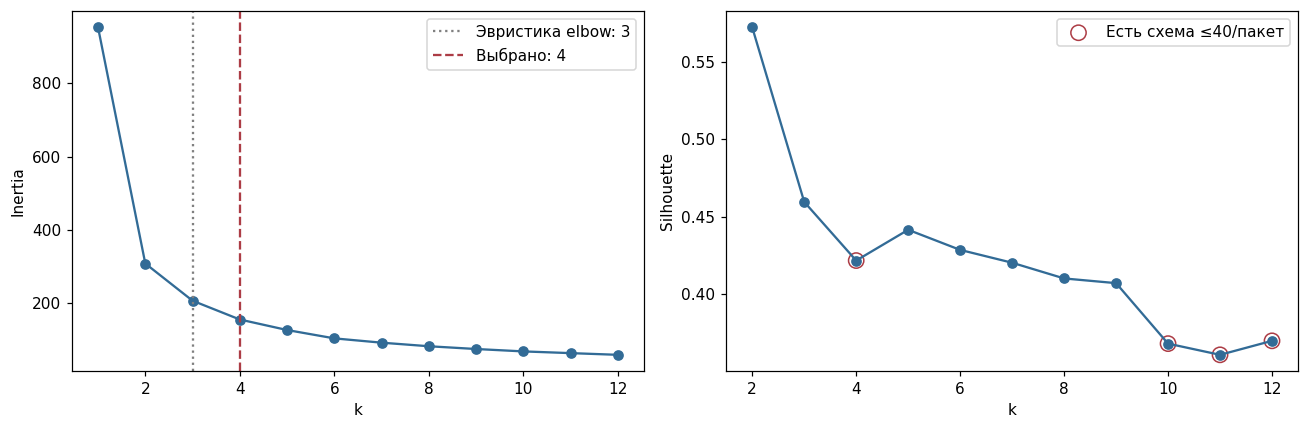

In [9]:
def exit_rule(data):
    return (data['gdp_per_capita_usd'].ge(10_000) & data['under5_mortality_per_1000'].le(10)
            & data['undernourishment_pct'].le(5) & data['access_sanitation_pct'].ge(90)
            & data['female_literacy_pct'].ge(95) & data['immunization_dtp3_pct'].ge(85)
            & data['immunization_measles_pct'].ge(85))

def action_plans(labels, data=filled, features=X):
    profile = data.assign(cluster=labels).groupby('cluster').median()
    severity = features.assign(cluster=labels).groupby('cluster').mean().mean(axis=1)
    order = severity.sort_values(ascending=False).index.to_numpy()
    counts = pd.Series(labels).value_counts().reindex(order).to_numpy()
    eligible = exit_rule(profile).reindex(order).to_numpy()
    plans = []
    # Границы делят упорядоченные группы на три пакета и группу рассмотрения выхода.
    for a, b, c in combinations(range(1, len(order)+1), 3):
        sizes = [counts[:a].sum(), counts[a:b].sum(), counts[b:c].sum(), counts[c:].sum()]
        if max(sizes[:3]) <= CAPACITY and c < len(order) and eligible[c:].all():
            plans.append({'cuts': (a, b, c), 'sizes': [int(v) for v in sizes]})
    return order, counts, eligible, plans

models = {}
rows = []
for k in range(1, 13):
    model = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Y)
    models[k] = model
    order, counts, eligible, plans = action_plans(model.labels_)
    rows.append({'k': k, 'inertia': model.inertia_,
                 'silhouette': silhouette_score(Y, model.labels_) if k > 1 else np.nan,
                 'Размеры по нуждаемости': ', '.join(map(str, counts)),
                 'Макс. группа': int(counts.max()), 'Последовательных схем': len(plans),
                 'Стран в 4 решениях (первая схема)': str(plans[0]['sizes']) if plans else '—'})
search = pd.DataFrame(rows)
display(search.round(3))
# «Локоть» оцениваем по наибольшему расстоянию от нормированной кривой до хорды.
kn = (search.k.to_numpy() - 1) / (search.k.max() - 1)
inorm = (search.inertia.to_numpy() - search.inertia.min()) / (search.inertia.max() - search.inertia.min())
elbow_k = int(search.iloc[np.argmax(1 - kn - inorm)].k)
feasible = search.loc[search['Последовательных схем'].gt(0)]
assert not feasible.empty, 'Для выбранного правила допустимой схемы нет: нельзя обещать выполнение бюджета.'
# Среди допустимых последовательных сценариев выбираем максимальный silhouette.
# ПО локтю смотрим перелом- это и будет наше количество оптимальных групп
K = int(feasible.sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0].k)
print('Максимум silhouette:', int(search.loc[search.silhouette.idxmax(), 'k']),
      '; эвристика elbow:', elbow_k, '; выбранное бюджетное k:', K)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(search.k, search.inertia, 'o-', color='#326b96')
axes[0].axvline(elbow_k, ls=':', color='grey', label=f'Эвристика elbow: {elbow_k}')
axes[0].axvline(K, ls='--', color='#ac3c45', label=f'Выбрано: {K}')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia'); axes[0].legend()
axes[1].plot(search.k[1:], search.silhouette[1:], 'o-', color='#326b96')
axes[1].scatter(feasible.k, feasible.silhouette, s=100, facecolors='none', edgecolors='#ac3c45', label='Есть схема ≤40/пакет')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette'); axes[1].legend()
plt.tight_layout(); plt.show()

,Стран,Предварительное решение,gdp_per_capita_usd,under5_mortality_per_1000,maternal_mortality_per_100k,immunization_dtp3_pct,immunization_measles_pct,undernourishment_pct,stunting_under5_pct,access_sanitation_pct,doctors_per_1000,female_literacy_pct
Группа,,,,,,,,,,,,
1,24,Гуманитарный режим,915.70,72.95,363.0,68.0,63.0,22.40,33.11,28.90,0.17,45.31
2,34,Инфраструктура и питание,1801.55,38.65,179.5,87.0,84.0,16.90,26.30,57.17,0.25,71.29
3,40,Кадры и системы,6758.85,14.10,36.5,93.0,93.0,4.85,11.43,94.25,1.87,94.15
4,50,Рассмотрение выхода,35444.55,3.90,6.0,95.0,94.5,2.50,2.74,99.10,3.65,97.75


Медианы только наблюдаемых значений — контроль влияния заполнения:


,gdp_per_capita_usd,under5_mortality_per_1000,maternal_mortality_per_100k,immunization_dtp3_pct,immunization_measles_pct,undernourishment_pct,stunting_under5_pct,access_sanitation_pct,doctors_per_1000,female_literacy_pct
Группа,,,,,,,,,,
1,957.20,72.95,363.0,68.0,63.0,22.3,33.95,28.90,0.17,41.50
2,1882.60,38.65,179.5,87.0,84.0,16.5,26.70,53.25,0.25,73.10
3,6758.85,14.10,36.5,93.0,93.0,4.6,10.15,94.10,1.88,94.65
4,35444.55,3.90,6.0,95.0,94.5,2.5,3.00,99.10,3.62,98.05


Процент заполненных значений по группам:


,stunting_under5_pct,female_literacy_pct,beds_per_1000
Группа,,,
1,25.0,20.8,45.8
2,20.6,14.7,44.1
3,20.0,15.0,7.5
4,72.0,76.0,2.0


,Стран
Рассмотрение выхода,50
Кадры и системы,40
Инфраструктура и питание,34
Гуманитарный режим,24


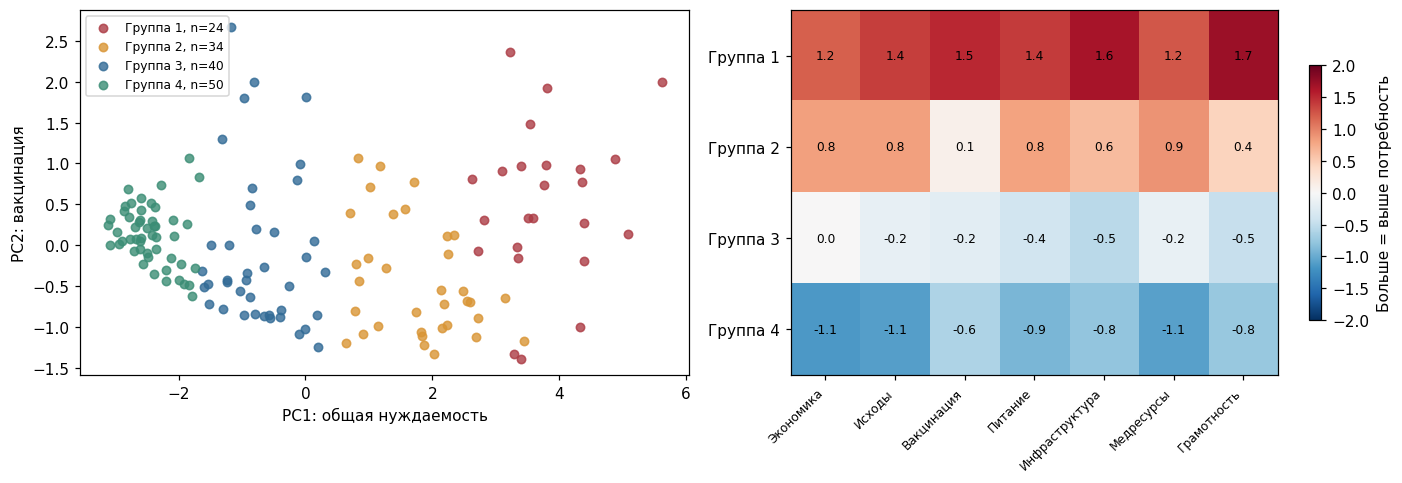

In [10]:
model = models[K]
order, counts, eligible, plans = action_plans(model.labels_)
# Номера делаем понятными: группа 1 — самая высокая нуждаемость.
renumber = {old: i + 1 for i, old in enumerate(order)}
labels = np.array([renumber[v] for v in model.labels_])
plan = plans[0]
a, b, c = plan['cuts']
actions = {}
for j in range(K):
    actions[j + 1] = ('Гуманитарный режим' if j < a else
                      'Инфраструктура и питание' if j < b else
                      'Кадры и системы' if j < c else 'Рассмотрение выхода')
profile = filled.assign(Группа=labels).groupby('Группа').median()
profile_observed = R.assign(Группа=labels).groupby('Группа').median()
group_counts = pd.Series(labels).value_counts().sort_index()
important = ['gdp_per_capita_usd', 'under5_mortality_per_1000', 'maternal_mortality_per_100k',
             'immunization_dtp3_pct', 'immunization_measles_pct', 'undernourishment_pct',
             'stunting_under5_pct', 'access_sanitation_pct', 'doctors_per_1000', 'female_literacy_pct']
summary = profile[important].copy()
summary.insert(0, 'Стран', group_counts)
summary.insert(1, 'Предварительное решение', pd.Series(actions))
display(summary.round(2))
print('Медианы только наблюдаемых значений — контроль влияния заполнения:')
display(profile_observed[important].round(2))
print('Процент заполненных значений по группам:')
display(R.isna().assign(Группа=labels).groupby('Группа')[focus_missing].mean().mul(100).round(1))
package_totals = pd.Series([actions[g] for g in labels]).value_counts()
display(package_totals.rename('Стран').to_frame())
assert all(package_totals.get(name, 0) <= CAPACITY for name in
           ['Гуманитарный режим', 'Инфраструктура и питание', 'Кадры и системы'])
group_blocks = X.assign(Группа=labels).groupby('Группа').mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
palette = ['#ac3c45', '#d99535', '#326b96', '#3b8d75']
for g in sorted(np.unique(labels)):
    mask = labels == g
    axes[0].scatter(scores_all[mask, 0], scores_all[mask, 1], label=f'Группа {g}, n={mask.sum()}',
                    color=palette[(g-1) % len(palette)], s=30, alpha=.8)
axes[0].set_xlabel('PC1: общая нуждаемость'); axes[0].set_ylabel('PC2: вакцинация'); axes[0].legend(fontsize=8)
im = axes[1].imshow(group_blocks, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
axes[1].set_xticks(range(X.shape[1]), X.columns, rotation=45, ha='right', fontsize=8)
axes[1].set_yticks(range(K), [f'Группа {g}' for g in group_blocks.index])
for i in range(K):
    for j in range(X.shape[1]):
        axes[1].text(j, i, f'{group_blocks.iloc[i,j]:.1f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=axes[1], shrink=.7, label='Больше = выше потребность')
plt.tight_layout(); plt.show()

### Содержательная проверка состава

Смотрим весь состав, а не только центры. Самая нуждающаяся группа имеет высокую смертность и слабую вакцинацию; следующая — выраженные проблемы питания и инфраструктуры при сравнительно лучшей вакцинации; третья — более развитые системы с оставшимися потребностями; четвёртая — низкая общая нуждаемость. Это относительные группы в данных фонда, не официальная классификация доходов.

Один пакет внутри группы не исключает индивидуальных акцентов. Например, хорошая вакцинация не означает отсутствие недостатка питания, а большой ВВП не гарантирует достаточный охват прививками.

In [11]:
for g in sorted(np.unique(labels)):
    print(f'Группа {g} ({group_counts[g]} стран) — {actions[g]}:')
    print('; '.join(df.loc[labels == g, 'country']))
    print()
for iso in ['GTM', 'IND']:
    i = df.index[df['iso3'].eq(iso)][0]
    print(df.loc[i, 'country'], '→ группа', labels[i], '→', actions[labels[i]])

# Медиана группы не является разрешением вывести каждую страну.
exit_candidate = np.array([actions[g] == 'Рассмотрение выхода' for g in labels])
individual_exit = exit_rule(filled).to_numpy()
exit_check = pd.concat([df[['country']], filled[['gdp_per_capita_usd', 'under5_mortality_per_1000',
                         'immunization_dtp3_pct', 'immunization_measles_pct', 'access_sanitation_pct']]], axis=1)
exit_check['Проходит индивидуальные ориентиры'] = individual_exit
exit_check['Есть заполненные критерии'] = R[['gdp_per_capita_usd', 'undernourishment_pct',
    'access_sanitation_pct', 'female_literacy_pct']].isna().any(axis=1)
print('В группе рассмотрения выхода:', int(exit_candidate.sum()),
      '; не проходят индивидуальные ориентиры:', int((exit_candidate & ~individual_exit).sum()))
display(exit_check.loc[exit_candidate & ~individual_exit].round(2))
print('Данные некоторых критериев восстановлены у', int((exit_candidate & exit_check['Есть заполненные критерии']).sum()),
      'стран группы выхода — нужны проверки источников.')

Группа 1 (24 стран) — Гуманитарный режим:
Ангола; Афганистан; Бенин; Буркина-Фасо; Гаити; Гвинея; Гвинея-Бисау; ДР Конго; Йемен; Кот-д'Ивуар; Мадагаскар; Мали; Мозамбик; Нигер; Нигерия; Папуа - Новая Гвинея; Республика Конго; Сомали; Судан; Сьерра-Леоне; Центральноафриканская Республика; Чад; Эфиопия; Южный Судан

Группа 2 (34 стран) — Инфраструктура и питание:
Бангладеш; Боливия; Бурунди; Вануату; Восточный Тимор; Габон; Гамбия; Гана; Гватемала; Гондурас; Замбия; Зимбабве; Индия; Камбоджа; Камерун; Кения; Лаос; Лесото; Либерия; Мавритания; Малави; Мьянма; Намибия; Непал; Пакистан; Руанда; Сенегал; Соломоновы Острова; Танзания; Того; Уганда; Экваториальная Гвинея; Эритрея; Эсватини

Группа 3 (40 стран) — Кадры и системы:
Азербайджан; Албания; Алжир; Аргентина; Армения; Босния и Герцеговина; Ботсвана; Бразилия; Бутан; Вьетнам; Доминиканская Республика; Египет; Индонезия; Иордания; Колумбия; Коста-Рика; Кыргызстан; Ливан; Маврикий; Малайзия; Марокко; Мексика; Молдова; Монголия; Никарагуа

,country,gdp_per_capita_usd,under5_mortality_per_1000,immunization_dtp3_pct,immunization_measles_pct,access_sanitation_pct,Проходит индивидуальные ориентиры,Есть заполненные критерии
13,Болгария,15854.0,5.9,92.0,92.0,86.1,False,True
18,Бруней,32890.5,10.1,99.0,97.0,100.0,False,True
46,Ирландия,106818.9,3.8,93.0,89.0,89.7,False,True
51,Казахстан,12879.4,9.6,99.0,99.0,97.9,False,True
57,Кипр,36623.7,4.6,95.0,82.0,99.5,False,True
102,Румыния,18244.4,6.9,79.0,78.0,90.5,False,False
105,Северная Македония,8674.4,3.4,86.0,73.0,99.0,False,False
107,Сербия,12281.7,5.4,93.0,84.0,97.9,False,False
142,Эстония,30264.0,2.1,84.0,85.0,99.0,False,True


Данные некоторых критериев восстановлены у 41 стран группы выхода — нужны проверки источников.


### Насколько уверенно найдены границы

Проверяем разные вопросы разными способами:

* silhouette по каждой стране — насколько она геометрически ближе к своему кластеру; отрицательные значения означают спорное назначение;
* разница расстояний до первого и второго центра — выраженность выбора, **не вероятность**;
* 30 независимых стартов k-means — устойчивость оптимизации;
* 100 bootstrap-выборок стран с возвращением — устойчивость состава. Каждый раз обучаем k-means на выборке и предсказываем группы всех 148 стран. Номера согласуем с основной моделью алгоритмом Венгера; считаем ARI и Jaccard;
* отдельные сценарии подготовки и 30 случайных донорных заполнений — зависимость групп от пропусков.

Bootstrap здесь условный: преобразования, PCA и число групп зафиксированы. Он проверяет устойчивость k-means, но не охватывает всю неопределённость исходных измерений или политики фонда. Проверки подготовки вынесены отдельно. Ни одна из этих оценок не даёт «вероятность правильной помощи».

Silhouette выбранной модели: 0.422; отрицательный у 6 стран; ≤0.1 у 13 стран.


,mean,median,min
Группа,,,
1,0.338,0.390,0.060
2,0.324,0.337,0.064
3,0.269,0.302,-0.125
4,0.650,0.718,0.241


,country,iso3,region,Группа,silhouette,Относительный отрыв от второго центра,Заполненных показателей
121,Турция,TUR,Европа и Центральная Азия,3,-0.125,0.096,0
7,Армения,ARM,Европа и Центральная Азия,3,-0.093,0.164,1
60,Коста-Рика,CRI,Латинская Америка и Карибский бассейн,3,-0.069,0.182,0
3,Албания,ALB,Европа и Центральная Азия,3,-0.056,0.291,1
6,Аргентина,ARG,Латинская Америка и Карибский бассейн,3,-0.035,0.112,2
132,Черногория,MNE,Европа и Центральная Азия,3,-0.012,0.027,0
114,Сьерра-Леоне,SLE,Африка к югу от Сахары,1,0.060,0.126,1
14,Боливия,BOL,Латинская Америка и Карибский бассейн,2,0.064,0.066,1
19,Буркина-Фасо,BFA,Африка к югу от Сахары,1,0.064,0.123,0
35,Гондурас,HND,Латинская Америка и Карибский бассейн,2,0.068,0.081,0


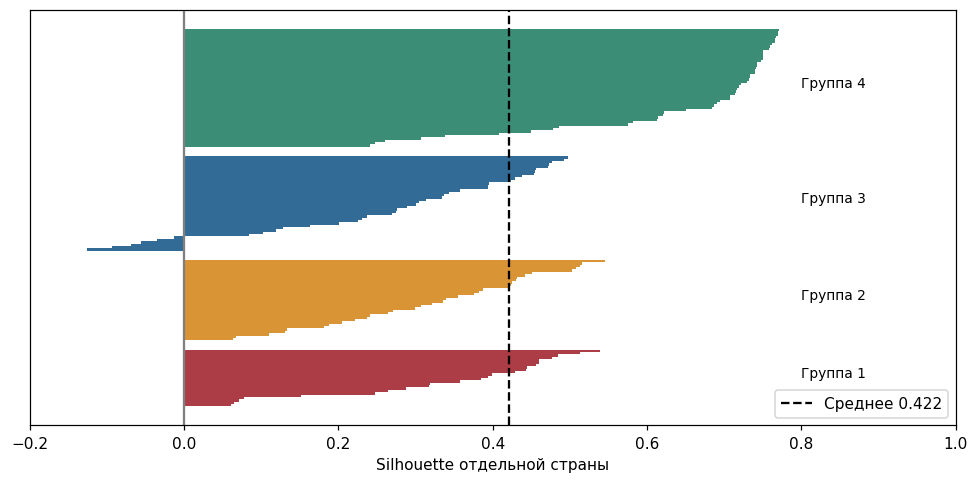

30 одиночных стартов:


,inertia,ARI
count,30.000,30.000
mean,157.597,0.827
std,7.584,0.150
min,154.677,0.520
25%,154.862,0.704
50%,155.165,0.865
75%,155.422,0.958
max,180.397,1.000


Bootstrap ARI: медиана и интервал 10–90%: [0.617 0.79  0.958]


,Jaccard p10,Jaccard медиана,Jaccard p90
1,0.667,0.875,1.000
2,0.545,0.750,1.000
3,0.560,0.783,0.952
4,0.818,0.915,1.000


Стран с долей совпадений <80%: 23


,country,iso3,region,Группа,silhouette,Относительный отрыв от второго центра,Заполненных показателей,Доля совпадений bootstrap
35,Гондурас,HND,Латинская Америка и Карибский бассейн,2,0.068,0.081,0,0.33
14,Боливия,BOL,Латинская Америка и Карибский бассейн,2,0.064,0.066,1,0.36
19,Буркина-Фасо,BFA,Африка к югу от Сахары,1,0.064,0.123,0,0.37
114,Сьерра-Леоне,SLE,Африка к югу от Сахары,1,0.060,0.126,1,0.37
6,Аргентина,ARG,Латинская Америка и Карибский бассейн,3,-0.035,0.112,2,0.38
132,Черногория,MNE,Европа и Центральная Азия,3,-0.012,0.027,0,0.38
121,Турция,TUR,Европа и Центральная Азия,3,-0.125,0.096,0,0.40
7,Армения,ARM,Европа и Центральная Азия,3,-0.093,0.164,1,0.43
60,Коста-Рика,CRI,Латинская Америка и Карибский бассейн,3,-0.069,0.182,0,0.44
61,Кот-д'Ивуар,CIV,Африка к югу от Сахары,1,0.078,0.203,1,0.48


Доля bootstrap-сценариев, где хотя бы один пакет >40: 0.44


,Пакет,p10,Медиана,p90
0,Гуманитарный режим,17.0,21.0,26.0
1,Инфраструктура и питание,26.0,32.0,35.0
2,Кадры и системы,36.0,40.0,44.0


In [12]:
sil = silhouette_samples(Y, labels)
distance = model.transform(Y)
two_dist = np.sort(distance, axis=1)[:, :2]
margin = (two_dist[:, 1] - two_dist[:, 0]) / np.maximum(two_dist[:, 1], 1e-12)
diagnostics = pd.concat([df[['country', 'iso3', 'region']], pd.DataFrame({
    'Группа': labels, 'silhouette': sil, 'Относительный отрыв от второго центра': margin,
    'Заполненных показателей': R.isna().sum(axis=1)})], axis=1)
print(f'Silhouette выбранной модели: {sil.mean():.3f}; отрицательный у {(sil < 0).sum()} стран; '
      f'≤0.1 у {(sil <= .1).sum()} стран.')
display(diagnostics.groupby('Группа')['silhouette'].agg(['mean', 'median', 'min']).round(3))
display(diagnostics.nsmallest(12, 'silhouette').round(3))
fig, ax = plt.subplots(figsize=(9, 4.5))
offset = 0
for g in sorted(np.unique(labels)):
    values = np.sort(sil[labels == g])
    ax.barh(np.arange(len(values)) + offset, values, color=palette[(g-1) % len(palette)], height=1)
    ax.text(.8, offset + len(values)/2, f'Группа {g}', fontsize=9)
    offset += len(values) + 4
ax.axvline(sil.mean(), ls='--', color='black', label=f'Среднее {sil.mean():.3f}')
ax.axvline(0, color='grey'); ax.set_xlim(-.2, 1); ax.set_yticks([])
ax.set_xlabel('Silhouette отдельной страны'); ax.legend()
plt.tight_layout(); plt.show()

start_rows = []
for seed in range(30):
    alt = KMeans(K, n_init=1, random_state=seed).fit(Y)
    start_rows.append([seed, alt.inertia_, adjusted_rand_score(labels, alt.labels_)])
starts = pd.DataFrame(start_rows, columns=['seed', 'inertia', 'ARI'])
print('30 одиночных стартов:')
display(starts[['inertia', 'ARI']].describe().round(3))

def align_labels(reference, candidate):
    ref_values = np.unique(reference)
    cand_values = np.unique(candidate)
    overlap = np.array([[(reference == r).astype(int) @ (candidate == c).astype(int)
                         for c in cand_values] for r in ref_values])
    ri, ci = linear_sum_assignment(-overlap)
    mapping = {cand_values[j]: ref_values[i] for i, j in zip(ri, ci)}
    return np.array([mapping[v] for v in candidate])

rng = np.random.default_rng(SEED)
B = 100
bootstrap_labels, bootstrap_ari, bootstrap_jaccard = [], [], []
for repeat in range(B):
    sample = rng.integers(0, len(Y), len(Y))
    alt = KMeans(K, n_init=20, random_state=repeat).fit(Y[sample])
    aligned = align_labels(labels, alt.predict(Y))
    bootstrap_labels.append(aligned)
    bootstrap_ari.append(adjusted_rand_score(labels, aligned))
    bootstrap_jaccard.append([np.sum((labels == g) & (aligned == g)) /
        np.sum((labels == g) | (aligned == g)) for g in sorted(np.unique(labels))])
bootstrap_labels = np.array(bootstrap_labels)
stability = (bootstrap_labels == labels[None, :]).mean(axis=0)
diagnostics['Доля совпадений bootstrap'] = stability
print('Bootstrap ARI: медиана и интервал 10–90%:', np.quantile(bootstrap_ari, [.1, .5, .9]).round(3))
jaccard_table = pd.DataFrame(np.quantile(bootstrap_jaccard, [.1, .5, .9], axis=0).T,
                             index=range(1, K+1), columns=['Jaccard p10', 'Jaccard медиана', 'Jaccard p90'])
display(jaccard_table.round(3))
print('Стран с долей совпадений <80%:', int((stability < .8).sum()))
display(diagnostics.nsmallest(15, 'Доля совпадений bootstrap').round(3))
# Лимит пакета может нарушиться при небольших изменениях границ.
boot_package_counts = np.array([[sum(actions[g] == name for g in row) for name in
    ['Гуманитарный режим', 'Инфраструктура и питание', 'Кадры и системы']] for row in bootstrap_labels])
print('Доля bootstrap-сценариев, где хотя бы один пакет >40:', np.any(boot_package_counts > CAPACITY, axis=1).mean().round(3))
display(pd.DataFrame({'Пакет': ['Гуманитарный режим', 'Инфраструктура и питание', 'Кадры и системы'],
    'p10': np.quantile(boot_package_counts, .1, axis=0),
    'Медиана': np.median(boot_package_counts, axis=0),
    'p90': np.quantile(boot_package_counts, .9, axis=0)}))

In [13]:
def fit_scenario(data, drop=()):
    alt_X, _, _ = make_features(data, drop)
    alt_pca = PCA().fit(alt_X)
    m = int(np.searchsorted(alt_pca.explained_variance_ratio_.cumsum(), .9) + 1)
    alt_Y = alt_pca.transform(alt_X)[:, :m]
    alt = KMeans(K, n_init=50, random_state=SEED).fit(alt_Y)
    aligned = align_labels(labels, alt.labels_)
    return aligned, m, silhouette_score(alt_Y, aligned)

scenarios = [
    ('Основной: 7 соседей внутри терциля', filled, ()),
    ('3 соседа внутри терциля', impute_data(R, n_neighbors=3), ()),
    ('12 соседей внутри терциля', impute_data(R, n_neighbors=12), ()),
    ('7 соседей без терцилей', impute_data(R, use_strata=False), ()),
    ('Общая медиана (контроль)', impute_data(R, mode='median'), ()),
    ('Без низкорослости, грамотности и коек', filled,
     ('stunting_under5_pct', 'female_literacy_pct', 'beds_per_1000')),
]
sensitivity_rows = []
for name, data, drop in scenarios:
    alt_labels, m, s = fit_scenario(data, drop)
    sizes = pd.Series(alt_labels).value_counts().reindex(range(1, K+1)).to_list()
    sensitivity_rows.append([name, m, s, adjusted_rand_score(labels, alt_labels),
                             int((alt_labels != labels).sum()), str(sizes)])
# Проверяем отдельно потерю информации при проекции PCA.
full_model = KMeans(K, n_init=50, random_state=SEED).fit(X)
full_labels = align_labels(labels, full_model.labels_)
sensitivity_rows.append(['Все 7 осей без PCA', 7, silhouette_score(X, full_labels),
                        adjusted_rand_score(labels, full_labels), int((full_labels != labels).sum()),
                        str(pd.Series(full_labels).value_counts().reindex(range(1, K+1)).to_list())])
sensitivity = pd.DataFrame(sensitivity_rows, columns=['Сценарий', 'Компонент', 'Silhouette', 'ARI к основному',
                              'Сменили группу', 'Размеры групп 1…k'])
display(sensitivity.round(3))

donor_ari, donor_assignments = [], []
for repeat in range(30):
    draw = impute_data(R, rng=np.random.default_rng(1000 + repeat))
    alt_labels, _, _ = fit_scenario(draw)
    donor_ari.append(adjusted_rand_score(labels, alt_labels))
    donor_assignments.append(alt_labels)
donor_assignments = np.array(donor_assignments)
diagnostics['Доля совпадений донорных сценариев'] = (donor_assignments == labels).mean(axis=0)
print('Случайные доноры, ARI p10/медиана/p90:', np.quantile(donor_ari, [.1, .5, .9]).round(3))
display(diagnostics.nsmallest(10, 'Доля совпадений донорных сценариев').round(3))

,Сценарий,Компонент,Silhouette,ARI к основному,Сменили группу,Размеры групп 1…k
0,Основной: 7 соседей внутри терциля,3,0.422,1.000,0,"[24, 34, 40, 50]"
1,3 соседа внутри терциля,3,0.417,0.969,2,"[25, 34, 39, 50]"
2,12 соседей внутри терциля,3,0.420,0.986,1,"[25, 33, 40, 50]"
3,7 соседей без терцилей,3,0.423,0.969,2,"[25, 34, 39, 50]"
4,Общая медиана (контроль),4,0.356,0.884,8,"[21, 35, 43, 49]"
5,"Без низкорослости, грамотности и коек",3,0.400,0.787,14,"[20, 35, 44, 49]"
6,Все 7 осей без PCA,7,0.339,1.000,0,"[24, 34, 40, 50]"


Случайные доноры, ARI p10/медиана/p90: [0.686 0.882 0.956]


,country,iso3,region,Группа,silhouette,Относительный отрыв от второго центра,Заполненных показателей,Доля совпадений bootstrap,Доля совпадений донорных сценариев
132,Черногория,MNE,Европа и Центральная Азия,3,-0.012,0.027,0,0.38,0.267
14,Боливия,BOL,Латинская Америка и Карибский бассейн,2,0.064,0.066,1,0.36,0.433
67,Либерия,LBR,Африка к югу от Сахары,2,0.131,0.106,1,0.88,0.433
6,Аргентина,ARG,Латинская Америка и Карибский бассейн,3,-0.035,0.112,2,0.38,0.467
7,Армения,ARM,Европа и Центральная Азия,3,-0.093,0.164,1,0.43,0.467
35,Гондурас,HND,Латинская Америка и Карибский бассейн,2,0.068,0.081,0,0.33,0.467
121,Турция,TUR,Европа и Центральная Азия,3,-0.125,0.096,0,0.40,0.500
19,Буркина-Фасо,BFA,Африка к югу от Сахары,1,0.064,0.123,0,0.37,0.533
22,Вануату,VUT,Восточная Азия и Океания,2,0.222,0.279,2,0.53,0.533
60,Коста-Рика,CRI,Латинская Америка и Карибский бассейн,3,-0.069,0.182,0,0.44,0.533


## 5. Второй метод: иерархическая кластеризация Ward

**Почему Ward:** он объединяет страны снизу вверх, каждый раз выбирая слияние с минимальным приростом внутригрупповой суммы квадратов. Можно увидеть структуру на дендрограмме и проверить несколько уровней разбиения. Метод не зависит от случайных начальных центров; ранние слияния, однако, уже нельзя отменить. Это не гарантия, что найденные группы истинны.

Для честного сравнения используем **те же 148 стран, те же заполненные показатели и те же 3 компоненты PCA**, что для k-means. Расстояние евклидово; Ward применяется к числовым координатам, не к заранее построенной матрице расстояний. Сначала сравниваем одинаковое число групп `K`, затем рассматриваем срезы дендрограммы k=2…12 и ограничения пакетов.

Номера групп не являются результатом сравнения: они произвольны. Поэтому считаем **ARI**, строим таблицу пересечений и для подсчёта сменивших группу согласуем номера по максимальному совпадению. ARI=1 означает одинаковое разбиение, около 0 — согласие на случайном уровне. Silhouette отражает разделённость, не эффективность поддержки.

In [14]:
# Строим одну иерархию, затем разрезаем её на разных уровнях.
ward_tree = linkage(Y, method='ward', optimal_ordering=True)
ward_raw = cut_tree(ward_tree, n_clusters=K).ravel()
ward_order, ward_counts, ward_eligible, ward_plans = action_plans(ward_raw)
ward_number = {old: i + 1 for i, old in enumerate(ward_order)}
ward_labels = np.array([ward_number[g] for g in ward_raw])
ward_aligned = align_labels(labels, ward_raw)
ward_sil = silhouette_samples(Y, ward_labels)
method_ari = adjusted_rand_score(labels, ward_labels)
method_disagreement = ward_aligned != labels

comparison = pd.DataFrame([
    ['k-means', K, silhouette_score(Y, labels), ', '.join(map(str, group_counts)),
     int((sil < 0).sum()), len(plans)],
    ['Ward', K, silhouette_score(Y, ward_labels), ', '.join(map(str, ward_counts)),
     int((ward_sil < 0).sum()), len(ward_plans)]
], columns=['Метод', 'Групп', 'Silhouette', 'Размеры от высокой к низкой потребности',
            'Отрицательный silhouette, стран', 'Последовательных схем ≤40/пакет'])
display(comparison.round(3))
print(f'ARI между методами при k={K}: {method_ari:.3f}')
print('Различаются назначения после согласования номеров:', int(method_disagreement.sum()), 'стран')

cross_table = pd.crosstab(pd.Series(labels, name='k-means, группа'),
                          pd.Series(ward_labels, name='Ward, группа'))
display(cross_table)
ward_profile = filled.assign(Группа=ward_labels).groupby('Группа').median()
display(ward_profile[important].round(2))
method_cases = diagnostics.copy()
method_cases['Ward: группа по потребности'] = ward_labels
method_cases['Ward: номер после согласования'] = ward_aligned
method_cases['Методы расходятся'] = method_disagreement
display(method_cases.loc[method_disagreement].sort_values('silhouette').round(3))

,Метод,Групп,Silhouette,Размеры от высокой к низкой потребности,"Отрицательный silhouette, стран",Последовательных схем ≤40/пакет
0,k-means,4,0.422,"24, 34, 40, 50",6,1
1,Ward,4,0.357,"22, 42, 49, 35",20,0


ARI между методами при k=4: 0.628
Различаются назначения после согласования номеров: 23 стран


"Ward, группа",1,2,3,4
"k-means, группа",,,,
1,22,2,0,0
2,0,34,0,0
3,0,6,34,0
4,0,0,15,35


,gdp_per_capita_usd,under5_mortality_per_1000,maternal_mortality_per_100k,immunization_dtp3_pct,immunization_measles_pct,undernourishment_pct,stunting_under5_pct,access_sanitation_pct,doctors_per_1000,female_literacy_pct
Группа,,,,,,,,,,
1,957.20,68.10,397.0,67.0,63.0,22.40,33.73,28.90,0.18,48.36
2,2004.75,38.15,162.5,87.0,83.5,15.65,24.95,58.28,0.28,73.62
3,9740.70,10.40,24.0,96.0,96.0,2.50,8.80,96.40,2.36,95.30
4,49919.70,3.70,4.0,94.0,94.0,2.50,2.52,99.10,3.88,97.78


,country,iso3,region,Группа,silhouette,Относительный отрыв от второго центра,Заполненных показателей,Доля совпадений bootstrap,Доля совпадений донорных сценариев,Ward: группа по потребности,Ward: номер после согласования,Методы расходятся
114,Сьерра-Леоне,SLE,Африка к югу от Сахары,1,0.060,0.126,1,0.37,0.533,2,2,True
19,Буркина-Фасо,BFA,Африка к югу от Сахары,1,0.064,0.123,0,0.37,0.533,2,2,True
90,Никарагуа,NIC,Латинская Америка и Карибский бассейн,3,0.163,0.260,5,0.95,0.833,2,2,True
68,Ливан,LBN,Ближний Восток и Северная Африка,3,0.231,0.282,0,0.96,1.000,2,2,True
10,Бахрейн,BHR,Ближний Восток и Северная Африка,4,0.241,0.147,2,0.94,0.967,3,3,True
77,Мальдивы,MDV,Южная Азия,4,0.248,0.149,2,0.94,0.933,3,3,True
105,Северная Македония,MKD,Европа и Центральная Азия,4,0.261,0.162,0,0.92,1.000,3,3,True
44,Индонезия,IDN,Восточная Азия и Океания,3,0.289,0.459,0,0.95,1.000,2,2,True
58,Китай,CHN,Восточная Азия и Океания,4,0.307,0.203,1,0.94,0.900,3,3,True
138,Эквадор,ECU,Латинская Америка и Карибский бассейн,3,0.335,0.457,0,0.97,1.000,2,2,True


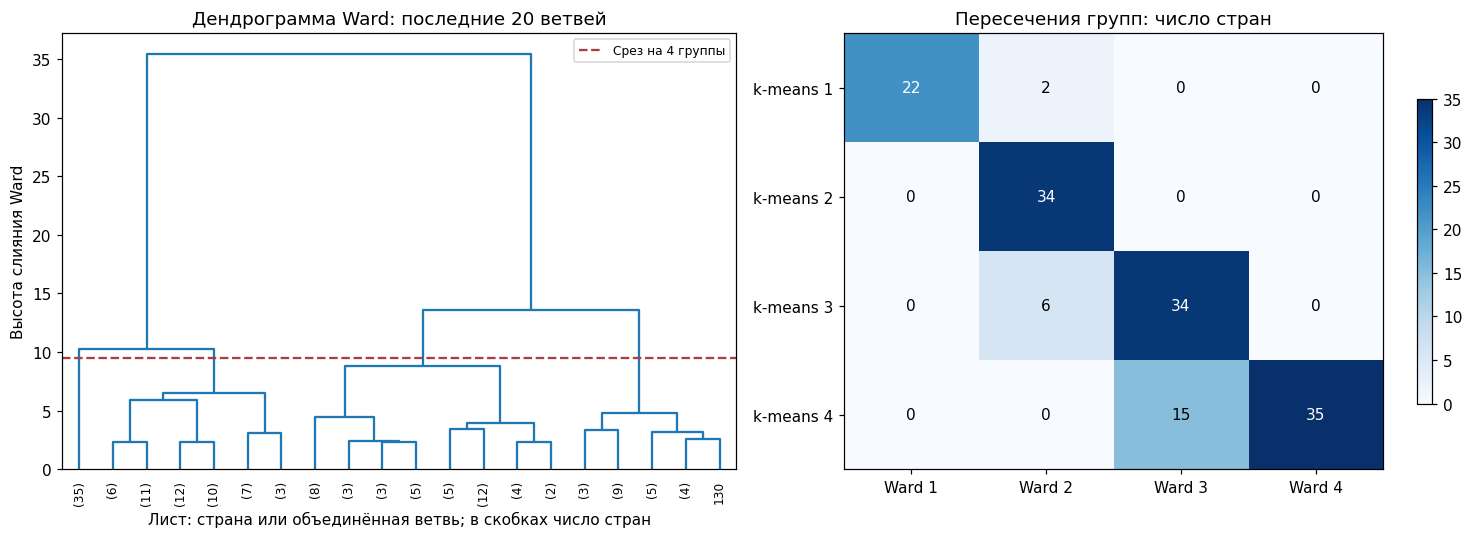

,k,Ward silhouette,k-means silhouette,ARI при одинаковом k,Размеры Ward по потребности,Последовательных схем Ward,Стран по 4 решениям: первая схема
0,2,0.553,0.572,0.843,"64, 84",0,—
1,3,0.471,0.460,0.419,"22, 42, 84",0,—
2,4,0.357,0.422,0.628,"22, 42, 49, 35",0,—
3,5,0.343,0.442,0.586,"22, 23, 19, 49, 35",0,—
4,6,0.368,0.429,0.656,"22, 23, 19, 10, 39, 35",0,—
5,7,0.365,0.420,0.635,"22, 23, 19, 17, 10, 22, 35",0,—
6,8,0.343,0.410,0.582,"10, 12, 23, 19, 17, 10, 22, 35",0,—
7,9,0.336,0.407,0.628,"10, 12, 23, 8, 11, 17, 10, 22, 35",1,"[22, 31, 38, 57]"
8,10,0.340,0.368,0.791,"10, 12, 6, 17, 8, 11, 17, 10, 22, 35",3,"[22, 31, 38, 57]"
9,11,0.344,0.361,0.757,"10, 12, 6, 12, 5, 8, 11, 17, 10, 22, 35",5,"[22, 31, 38, 57]"


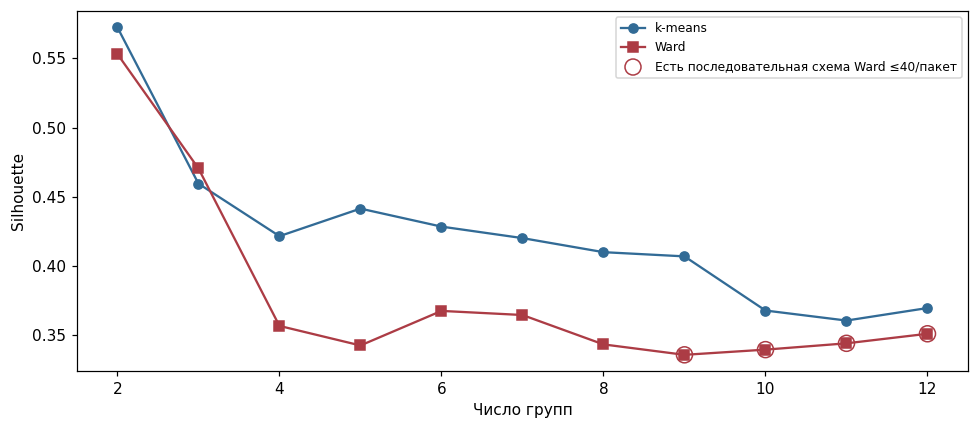

**Вывод сравнения:** при k=4 ARI=0.628, геометрическая разделённость Ward (0.357) ниже k-means (0.422). Первая бюджетно допустимая последовательная схема Ward появляется при k=9; наибольший silhouette среди допустимых срезов Ward — при k=12. Дробление крупных групп само по себе не решает проблему: если подгруппы получают один пакет, сумма стран в нём всё равно должна быть не больше 40. Для рабочего плана сохраняем k-means: он даёт более компактную схему с четырьмя группами и лучшую разделённость. Ward служит проверкой того, насколько границы зависят от метода.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
dendrogram(ward_tree, truncate_mode='lastp', p=20, show_leaf_counts=True,
           leaf_rotation=90, leaf_font_size=8, ax=axes[0], color_threshold=0)
# Для 4 кластеров порог проходит между высотами двух соседних слияний.
cut_height = (ward_tree[-K, 2] + ward_tree[-(K-1), 2]) / 2
axes[0].axhline(cut_height, ls='--', color='#ac3c45', label=f'Срез на {K} группы')
axes[0].set_title('Дендрограмма Ward: последние 20 ветвей')
axes[0].set_ylabel('Высота слияния Ward'); axes[0].legend(fontsize=8)
axes[0].set_xlabel('Лист: страна или объединённая ветвь; в скобках число стран')
im = axes[1].imshow(cross_table, cmap='Blues', aspect='auto')
axes[1].set_xticks(range(K), [f'Ward {g}' for g in range(1, K+1)])
axes[1].set_yticks(range(K), [f'k-means {g}' for g in range(1, K+1)])
for i in range(K):
    for j in range(K):
        axes[1].text(j, i, str(cross_table.iloc[i, j]), ha='center', va='center',
                     color='white' if cross_table.iloc[i, j] > cross_table.to_numpy().max()/2 else 'black')
axes[1].set_title('Пересечения групп: число стран')
fig.colorbar(im, ax=axes[1], shrink=.7)
plt.tight_layout(); plt.show()

# и методы локтя указывают практически то же самое
ward_rows = []
for k in range(2, 13):
    w = cut_tree(ward_tree, n_clusters=k).ravel()
    wo, wc, we, wp = action_plans(w)
    km = models[k].labels_
    ward_rows.append([k, silhouette_score(Y, w), silhouette_score(Y, km),
                      adjusted_rand_score(w, km), ', '.join(map(str, wc)), len(wp),
                      str(wp[0]['sizes']) if wp else '—'])
ward_search = pd.DataFrame(ward_rows, columns=['k', 'Ward silhouette', 'k-means silhouette',
                           'ARI при одинаковом k', 'Размеры Ward по потребности',
                           'Последовательных схем Ward', 'Стран по 4 решениям: первая схема'])
display(ward_search.round(3))
ward_feasible = ward_search.loc[ward_search['Последовательных схем Ward'].gt(0)]
ward_first_feasible_k = int(ward_feasible.k.min()) if len(ward_feasible) else None
ward_best_feasible_k = int(ward_feasible.sort_values('Ward silhouette', ascending=False).iloc[0].k) if len(ward_feasible) else None
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ward_search.k, ward_search['k-means silhouette'], 'o-', label='k-means', color='#326b96')
ax.plot(ward_search.k, ward_search['Ward silhouette'], 's-', label='Ward', color='#ac3c45')
ax.scatter(ward_feasible.k, ward_feasible['Ward silhouette'], s=110, facecolors='none',
           edgecolors='#ac3c45', label='Есть последовательная схема Ward ≤40/пакет')
ax.set_xlabel('Число групп'); ax.set_ylabel('Silhouette'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(Markdown(f'**Вывод сравнения:** при k={K} ARI={method_ari:.3f}, '
    f'геометрическая разделённость Ward ({ward_sil.mean():.3f}) ниже k-means ({sil.mean():.3f}). '
    f'Первая бюджетно допустимая последовательная схема Ward появляется при k={ward_first_feasible_k}; '
    f'наибольший silhouette среди допустимых срезов Ward — при k={ward_best_feasible_k}. '
    'Дробление крупных групп само по себе не решает проблему: если подгруппы получают один пакет, '
    'сумма стран в нём всё равно должна быть не больше 40. '
    'Для рабочего плана сохраняем k-means: он даёт более компактную схему с четырьмя группами '
    'и лучшую разделённость. Ward служит проверкой того, насколько границы зависят от метода.'))

**Ограничение независимой проверки.** Методы используют одни исходные данные и одну подготовку, поэтому их совпадение не является независимым подтверждением достоверности источника. Ward при четырёх группах даёт подгруппы в **42 и 49 стран**: нельзя просто переименовать их в два пакета и объявить бюджет выполненным. Проверка срезов более высокого k допускает несколько групп на один пакет, но сохраняет все прежние допущения о рассмотрении выхода.

## 6. Профили групп, пакеты и проверка

Для решений фонда используем рабочее разбиение k-means. Названия ниже описывают потребность; номер остаётся только техническим ключом. Профиль показываем в исходных интерпретируемых единицах, включая **медиану и межквартильный интервал**: разные страны внутри группы нельзя считать идентичными.

Медианы заполненных значений помогают составить полный профиль, а таблицы наблюдаемых медиан и долей пропусков из пункта 4 показывают, где профиль основан на допущениях. Особенно осторожно читаем питание и грамотность благополучных стран: значительная часть значений там восстановлена.

In [16]:
PROFILE_NAMES = {
    'Гуманитарный режим': 'Острые дефициты здоровья и базовых условий',
    'Инфраструктура и питание': 'Высокая потребность в питании и инфраструктуре',
    'Кадры и системы': 'Остаточные дефициты медицинских ресурсов и систем',
    'Рассмотрение выхода': 'Низкая общая потребность с индивидуальными исключениями',
}
group_names = {g: PROFILE_NAMES[actions[g]] for g in range(1, K+1)}
READABLE = {
    'gdp_per_capita_usd': 'ВВП, USD/жителя',
    'life_expectancy_years': 'Продолжительность жизни, лет',
    'under5_mortality_per_1000': 'Смертность до 5 лет / 1000',
    'maternal_mortality_per_100k': 'Материнская смертность / 100000',
    'immunization_dtp3_pct': 'DTP3, %',
    'immunization_measles_pct': 'Корь, %',
    'undernourishment_pct': 'Недоедание, % населения',
    'stunting_under5_pct': 'Низкорослость, % детей до 5 лет',
    'access_clean_water_pct': 'Доступ к воде, %',
    'access_sanitation_pct': 'Санитария, %',
    'doctors_per_1000': 'Врачей / 1000 жителей',
    'nurses_per_1000': 'Медсестёр / 1000 жителей',
    'beds_per_1000': 'Коек / 1000 жителей',
    'female_literacy_pct': 'Женская грамотность, %',
}
profile_table = profile[list(READABLE)].rename(columns=READABLE).round(2)
profile_table.index = [group_names[g] for g in profile_table.index]
profile_table.insert(0, 'Стран', group_counts.to_numpy())
display(profile_table)

for g in range(1, K+1):
    sample = filled.loc[labels == g]
    p = profile.loc[g]
    q = sample[list(READABLE)].quantile([.25, .75])
    display(Markdown(f"""### {group_names[g]} — {group_counts[g]} стран

Медианный ВВП — **{p.gdp_per_capita_usd:,.0f} USD/жителя**, продолжительность жизни —
**{p.life_expectancy_years:.1f} года**, смертность до 5 лет — **{p.under5_mortality_per_1000:.1f}/1000**
(центральные 50% стран: {q.loc[.25, 'under5_mortality_per_1000']:.1f}–{q.loc[.75, 'under5_mortality_per_1000']:.1f}).
DTP3 — **{p.immunization_dtp3_pct:.1f}%**, корь — **{p.immunization_measles_pct:.1f}%**;
низкорослость — **{p.stunting_under5_pct:.1f}%**
(центральные 50%: {q.loc[.25, 'stunting_under5_pct']:.1f}–{q.loc[.75, 'stunting_under5_pct']:.1f}%),
санитария — **{p.access_sanitation_pct:.1f}%**, врачей — **{p.doctors_per_1000:.2f}/1000 жителей**.

**Предварительное решение фонда:** {actions[g]}.
"""))

package_rationale = pd.DataFrame([
    ['Гуманитарный режим', 'Сочетание высокой смертности, слабой вакцинации и базовых дефицитов: интенсивная помощь с экстренной вакцинацией.'],
    ['Инфраструктура и питание', 'Недоедание и низкорослость вместе с плохими базовыми условиями: питание детей и инфраструктура; охват вакцинации проверяется отдельно.'],
    ['Кадры и системы', 'Базовые условия лучше, но ресурсы и результаты здоровья уступают благополучным странам: укрепление кадров и устойчивости систем, с разбором локальных провалов вакцинации.'],
    ['Рассмотрение выхода', 'Низкая общая потребность: проверить актуальные данные и индивидуальные исключения, затем рассматривать завершение программ; автоматического выхода нет.']
], columns=['Решение', 'Почему оно соответствует профилю'])
display(package_rationale)

,Стран,"ВВП, USD/жителя","Продолжительность жизни, лет",Смертность до 5 лет / 1000,Материнская смертность / 100000,"DTP3, %","Корь, %","Недоедание, % населения","Низкорослость, % детей до 5 лет","Доступ к воде, %","Санитария, %",Врачей / 1000 жителей,Медсестёр / 1000 жителей,Коек / 1000 жителей,"Женская грамотность, %"
Острые дефициты здоровья и базовых условий,24,915.70,61.90,72.95,363.0,68.0,63.0,22.40,33.11,65.70,28.90,0.17,0.76,0.64,45.31
Высокая потребность в питании и инфраструктуре,34,1801.55,67.65,38.65,179.5,87.0,84.0,16.90,26.30,82.27,57.17,0.25,1.50,0.85,71.29
Остаточные дефициты медицинских ресурсов и систем,40,6758.85,75.20,14.10,36.5,93.0,93.0,4.85,11.43,96.05,94.25,1.87,3.34,2.26,94.15
Низкая общая потребность с индивидуальными исключениями,50,35444.55,81.65,3.90,6.0,95.0,94.5,2.50,2.74,100.00,99.10,3.65,8.13,4.02,97.75


### Острые дефициты здоровья и базовых условий — 24 стран

Медианный ВВП — **916 USD/жителя**, продолжительность жизни —
**61.9 года**, смертность до 5 лет — **73.0/1000**
(центральные 50% стран: 54.8–94.1).
DTP3 — **68.0%**, корь — **63.0%**;
низкорослость — **33.1%**
(центральные 50%: 25.9–38.1%),
санитария — **28.9%**, врачей — **0.17/1000 жителей**.

**Предварительное решение фонда:** Гуманитарный режим.


### Высокая потребность в питании и инфраструктуре — 34 стран

Медианный ВВП — **1,802 USD/жителя**, продолжительность жизни —
**67.7 года**, смертность до 5 лет — **38.6/1000**
(центральные 50% стран: 30.5–49.4).
DTP3 — **87.0%**, корь — **84.0%**;
низкорослость — **26.3%**
(центральные 50%: 20.5–33.1%),
санитария — **57.2%**, врачей — **0.25/1000 жителей**.

**Предварительное решение фонда:** Инфраструктура и питание.


### Остаточные дефициты медицинских ресурсов и систем — 40 стран

Медианный ВВП — **6,759 USD/жителя**, продолжительность жизни —
**75.2 года**, смертность до 5 лет — **14.1/1000**
(центральные 50% стран: 11.5–18.2).
DTP3 — **93.0%**, корь — **93.0%**;
низкорослость — **11.4%**
(центральные 50%: 8.3–14.6%),
санитария — **94.3%**, врачей — **1.87/1000 жителей**.

**Предварительное решение фонда:** Кадры и системы.


### Низкая общая потребность с индивидуальными исключениями — 50 стран

Медианный ВВП — **35,445 USD/жителя**, продолжительность жизни —
**81.7 года**, смертность до 5 лет — **3.9/1000**
(центральные 50% стран: 3.0–5.7).
DTP3 — **95.0%**, корь — **94.5%**;
низкорослость — **2.7%**
(центральные 50%: 2.0–3.4%),
санитария — **99.1%**, врачей — **3.65/1000 жителей**.

**Предварительное решение фонда:** Рассмотрение выхода.


,Решение,Почему оно соответствует профилю
0,Гуманитарный режим,"Сочетание высокой смертности, слабой вакцинаци..."
1,Инфраструктура и питание,Недоедание и низкорослость вместе с плохими ба...
2,Кадры и системы,"Базовые условия лучше, но ресурсы и результаты..."
3,Рассмотрение выхода,Низкая общая потребность: проверить актуальные...


In [17]:
country_plan = df[['country', 'iso3', 'region', 'population']].copy()
country_plan['Группа k-means'] = labels
country_plan['Профиль'] = [group_names[g] for g in labels]
country_plan['Предварительное решение'] = [actions[g] for g in labels]
country_plan['Группа Ward'] = ward_labels
country_plan['Согласие методов после сопоставления'] = ~method_disagreement
country_plan['Silhouette k-means'] = sil
country_plan['Совпадения bootstrap'] = stability
country_plan['Совпадения донорных сценариев'] = diagnostics['Доля совпадений донорных сценариев'].to_numpy()
country_plan['Заполнено показателей'] = R.isna().sum(axis=1)
country_plan['Требует разбора границы'] = (sil <= .1) | (stability < .8) | method_disagreement
country_plan['Исключение перед выходом'] = exit_candidate & ~individual_exit

allocation = country_plan.groupby('Предварительное решение', sort=False).agg(
    Стран=('iso3', 'size'), Население=('population', 'sum'),
    Спорная_граница=('Требует разбора границы', 'sum'))
allocation['Лимит стран'] = [CAPACITY if name != 'Рассмотрение выхода' else np.nan for name in allocation.index]
allocation['Осталось мест'] = allocation['Лимит стран'] - allocation['Стран']
display(allocation)
# Проверяем именно пакет, а не максимальный размер отдельного кластера.
funded_names = ['Гуманитарный режим', 'Инфраструктура и питание', 'Кадры и системы']
assert country_plan['iso3'].nunique() == 148
assert allocation['Стран'].sum() == 148
assert allocation.loc[funded_names, 'Стран'].le(CAPACITY).all()

print('Страны с исключениями перед выходом:')
display(country_plan.loc[country_plan['Исключение перед выходом'],
       ['country', 'Профиль', 'Предварительное решение', 'Заполнено показателей']])
# Показываем конкретный критерий, на котором не проходит каждая страна.
criterion_checks = pd.DataFrame({
    'ВВП ≥10000': filled.gdp_per_capita_usd.ge(10000),
    'Смертность до 5 лет ≤10': filled.under5_mortality_per_1000.le(10),
    'Недоедание ≤5%': filled.undernourishment_pct.le(5),
    'Санитария ≥90%': filled.access_sanitation_pct.ge(90),
    'Грамотность ≥95%': filled.female_literacy_pct.ge(95),
    'DTP3 ≥85%': filled.immunization_dtp3_pct.ge(85),
    'Корь ≥85%': filled.immunization_measles_pct.ge(85),
})
exit_exceptions = country_plan.loc[country_plan['Исключение перед выходом'], ['country', 'iso3']].copy()
exit_exceptions['Не выполнены ориентиры'] = criterion_checks.loc[exit_exceptions.index].apply(
    lambda row: '; '.join(row.index[~row]), axis=1)
display(exit_exceptions)
print('Все страны с профилями, решениями и диагностикой:')
display(country_plan)

,Стран,Население,Спорная_граница,Лимит стран,Осталось мест
Предварительное решение,,,,,
Рассмотрение выхода,50,2606121834,15,NaN,NaN
Кадры и системы,40,1557108263,14,40.0,0.0
Гуманитарный режим,24,920607886,4,40.0,16.0
Инфраструктура и питание,34,2381886456,11,40.0,6.0


Страны с исключениями перед выходом:


,country,Профиль,Предварительное решение,Заполнено показателей
13,Болгария,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,2
18,Бруней,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,3
46,Ирландия,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,2
51,Казахстан,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,2
57,Кипр,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,2
102,Румыния,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,1
105,Северная Македония,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,0
107,Сербия,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,0
142,Эстония,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,2


,country,iso3,Не выполнены ориентиры
13,Болгария,BGR,Санитария ≥90%
18,Бруней,BRN,Смертность до 5 лет ≤10
46,Ирландия,IRL,Санитария ≥90%
51,Казахстан,KAZ,Грамотность ≥95%
57,Кипр,CYP,Корь ≥85%
102,Румыния,ROU,DTP3 ≥85%; Корь ≥85%
105,Северная Македония,MKD,ВВП ≥10000; Корь ≥85%
107,Сербия,SRB,Корь ≥85%
142,Эстония,EST,DTP3 ≥85%


Все страны с профилями, решениями и диагностикой:


,country,iso3,region,population,Группа k-means,Профиль,Предварительное решение,Группа Ward,Согласие методов после сопоставления,Silhouette k-means,Совпадения bootstrap,Совпадения донорных сценариев,Заполнено показателей,Требует разбора границы,Исключение перед выходом
0,Австралия,AUS,Восточная Азия и Океания,26659922,4,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,4,True,0.750768,1.00,1.000000,3,False,False
1,Австрия,AUT,Европа и Центральная Азия,9131761,4,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,4,True,0.683751,1.00,1.000000,2,False,False
2,Азербайджан,AZE,Европа и Центральная Азия,10153958,3,Остаточные дефициты медицинских ресурсов и систем,Кадры и системы,3,True,0.128624,0.84,1.000000,0,False,False
3,Албания,ALB,Европа и Центральная Азия,2411658,3,Остаточные дефициты медицинских ресурсов и систем,Кадры и системы,3,True,-0.055794,0.49,0.600000,1,True,False
4,Алжир,DZA,Ближний Восток и Северная Африка,46164219,3,Остаточные дефициты медицинских ресурсов и систем,Кадры и системы,3,True,0.393491,1.00,1.000000,1,False,False
5,Ангола,AGO,Африка к югу от Сахары,36749906,1,Острые дефициты здоровья и базовых условий,Гуманитарный режим,1,True,0.151226,0.87,0.966667,1,False,False
6,Аргентина,ARG,Латинская Америка и Карибский бассейн,45538401,3,Остаточные дефициты медицинских ресурсов и систем,Кадры и системы,3,True,-0.034834,0.38,0.466667,2,True,False
7,Армения,ARM,Европа и Центральная Азия,2964300,3,Остаточные дефициты медицинских ресурсов и систем,Кадры и системы,3,True,-0.093077,0.43,0.466667,1,True,False
8,Афганистан,AFG,Ближний Восток и Северная Африка,41454761,1,Острые дефициты здоровья и базовых условий,Гуманитарный режим,1,True,0.538710,1.00,1.000000,0,False,False
9,Бангладеш,BGD,Южная Азия,171466990,2,Высокая потребность в питании и инфраструктуре,Инфраструктура и питание,2,True,0.109594,0.50,0.566667,0,True,False


**Проверка бюджета означает:** Рабочая схема 24/34/40 стран укладывается в лимит при условии, что ещё 50 стран пока рассматриваются на выход. Это не завершённое решение о прекращении помощи. Девять индивидуальных исключений не доказывают, что этим странам нужен пакет, но не позволяют оформить выход автоматически. Если все девять после проверки потребуют лёгкого пакета, получится **49 стран вместо 40**; потребуется пересмотр состава пакетов и приоритетов. Переносить их в более интенсивный пакет только ради свободных мест нельзя без содержательного обоснования.

Вместимость в странах не равна финансовой стоимости: население стран сильно различается. Таблица показывает суммарное население для планирования масштаба; данных о стоимости программ нет, поэтому денежный бюджет здесь не рассчитан.

### Проверка Гватемалы, Индии и стран для переноса опыта

Проверяем не только совместное попадание в группу, но и сами показатели, согласие двух методов и устойчивость этой пары при изменении выборки и заполнения. Группы не подбирались так, чтобы заранее объединить эти две страны.

In [18]:
anchor_indices = [df.index[df['iso3'].eq(iso)][0] for iso in ['GTM', 'IND']]
gi, ii = anchor_indices
anchor_check = country_plan.loc[anchor_indices, ['country', 'Группа k-means', 'Профиль',
            'Предварительное решение', 'Группа Ward', 'Silhouette k-means', 'Совпадения bootstrap']].copy()
for col in ['stunting_under5_pct', 'undernourishment_pct', 'access_sanitation_pct',
            'immunization_dtp3_pct', 'immunization_measles_pct']:
    anchor_check[READABLE[col]] = filled.loc[anchor_indices, col]
display(anchor_check.round(3))
same_kmeans = bool(labels[gi] == labels[ii])
same_ward = bool(ward_labels[gi] == ward_labels[ii])
pair_bootstrap = (bootstrap_labels[:, gi] == bootstrap_labels[:, ii]).mean()
pair_donor = (donor_assignments[:, gi] == donor_assignments[:, ii]).mean()
print('Одна группа в k-means:', same_kmeans, '; одна группа в Ward:', same_ward)
print(f'Совместно в одной группе: {pair_bootstrap:.0%} bootstrap-сценариев и {pair_donor:.0%} донорных сценариев.')
print('Это эмпирические частоты сценариев, не вероятность успеха программы.')

# Для переноса детского питания сравниваем отдельные показатели внутри четырёх блоков.
# Квадраты отклонений не дают низкой низкорослости компенсироваться высоким недоеданием.
program_cols = ['stunting_under5_pct', 'undernourishment_pct', 'gdp_per_capita_usd',
                'access_clean_water_pct', 'access_sanitation_pct', 'female_literacy_pct']
program_data = filled[program_cols].copy()
program_data['gdp_per_capita_usd'] = np.log1p(program_data['gdp_per_capita_usd'])
program_scaler = StandardScaler()
program_z = program_scaler.fit_transform(program_data)
# В каждом блоке сумма весов равна 1: питание .5+.5, инфраструктура .5+.5, экономика 1, грамотность 1.
program_weights = np.array([.5, .5, 1, .5, .5, 1])
nutrition_X = program_z * np.sqrt(program_weights)
analogs = df[['country', 'iso3']].copy()
dist_g = np.linalg.norm(nutrition_X - nutrition_X[gi], axis=1)
dist_i = np.linalg.norm(nutrition_X - nutrition_X[ii], axis=1)
analogs['Расстояние до Гватемалы'] = dist_g
analogs['Расстояние до Индии'] = dist_i
analogs['Ближайший опыт'] = np.where(dist_g <= dist_i, 'Гватемала', 'Индия')
analogs['Минимальное расстояние'] = np.minimum(dist_g, dist_i)
analogs['Низкорослость, %'] = filled.stunting_under5_pct
analogs['Недоедание, %'] = filled.undernourishment_pct
analogs['Санитария, %'] = filled.access_sanitation_pct
analog_raw_cols = ['stunting_under5_pct', 'undernourishment_pct', 'access_clean_water_pct',
                  'access_sanitation_pct', 'gdp_per_capita_usd', 'female_literacy_pct']
analogs['Пропусков в профиле программы'] = R[analog_raw_cols].isna().sum(axis=1)
analogs['Методы согласны'] = ~method_disagreement
candidate_mask = ~df.iso3.isin(['GTM', 'IND']) & np.isin(labels, labels[anchor_indices])
analog_shortlist = analogs.loc[candidate_mask].nsmallest(10, 'Минимальное расстояние')
display(analog_shortlist.round(3))
print('Первые кандидаты для изучения:', '; '.join(analog_shortlist.head(5).country))

,country,Группа k-means,Профиль,Предварительное решение,Группа Ward,Silhouette k-means,Совпадения bootstrap,"Низкорослость, % детей до 5 лет","Недоедание, % населения","Санитария, %","DTP3, %","Корь, %"
31,Гватемала,2,Высокая потребность в питании и инфраструктуре,Инфраструктура и питание,2,0.241,0.53,46.0,11.8,70.6,88.0,89.0
43,Индия,2,Высокая потребность в питании и инфраструктуре,Инфраструктура и питание,2,0.205,0.54,35.5,12.0,80.7,91.0,93.0


Одна группа в k-means: True ; одна группа в Ward: True
Совместно в одной группе: 99% bootstrap-сценариев и 100% донорных сценариев.
Это эмпирические частоты сценариев, не вероятность успеха программы.


,country,iso3,Расстояние до Гватемалы,Расстояние до Индии,Ближайший опыт,Минимальное расстояние,"Низкорослость, %","Недоедание, %","Санитария, %",Пропусков в профиле программы,Методы согласны
64,Лаос,LAO,1.200,0.477,Индия,0.477,32.800,13.476,87.000,1,True
9,Бангладеш,BGD,1.343,0.767,Индия,0.767,23.600,10.400,65.600,0,True
25,Восточный Тимор,TLS,1.210,1.039,Индия,1.039,46.700,18.700,70.500,0,True
86,Непал,NPL,1.800,1.093,Индия,1.093,24.800,5.300,82.600,0,True
35,Гондурас,HND,1.621,1.107,Индия,1.107,18.700,14.800,86.800,0,True
52,Камбоджа,KHM,1.723,1.171,Индия,1.171,21.900,5.200,80.400,0,True
84,Мьянма,MMR,1.674,1.230,Индия,1.230,26.700,5.400,74.200,0,True
22,Вануату,VUT,1.489,1.335,Индия,1.335,23.297,7.200,48.200,1,True
94,Пакистан,PAK,1.791,1.366,Индия,1.366,37.600,16.500,71.800,0,True
139,Экваториальная Гвинея,GNQ,1.608,1.412,Индия,1.412,18.791,16.992,58.257,5,True


Первые кандидаты для изучения: Лаос; Бангладеш; Восточный Тимор; Непал; Гондурас


Список аналогов ранжирует сходство с **хотя бы одной** опорной страной по четырём блокам, связанным с питанием; он отличается от расстояния по всему профилю развития. В каждом блоке общий вес равен 1, а внутри питания и инфраструктуры суммируются квадраты отдельных отклонений. Это не позволяет противоположным отклонениям низкорослости и недоедания полностью компенсироваться при усреднении. Таблица показывает, к чьему опыту ближе кандидат и какие значения пришлось восстанавливать. Страны с пропусками и расхождением методов требуют дополнительной проверки.

Устойчивость пары и устойчивость пакета — разные вещи: Гватемала и Индия вместе в 99% bootstrap-сценариев, но остаются именно в исходной группе питания лишь в 53% и 54% соответственно. Они часто перемещаются вместе; это подтверждает их сходство сильнее, чем границу между уровнями помощи.

Совпадение Гватемалы и Индии поддерживает содержательную интерпретацию группы, но не доказывает одинаковый эффект вмешательства. Для решения о переносе программы нужны данные о механизме дефицита питания, результатах действующих программ, логистике, охвате и стоимости; в этом датасете их нет.

## 7. Заключение для совета фонда

Ниже — короткое заключение с численностью, решениями и оценкой доверия. Все числа берутся из рассчитанных таблиц, а не вводятся вручную.

In [19]:
# создаём датафрейм для удобной работы с данными и удобного исследования их 
board_groups = pd.DataFrame({
    'Профиль': [group_names[g] for g in range(1, K+1)],
    'Стран': [int(group_counts[g]) for g in range(1, K+1)],
    'Предлагаемое решение': [actions[g] for g in range(1, K+1)],
    'Смертность до 5 лет /1000, медиана': profile.under5_mortality_per_1000.to_numpy(),
    'Низкорослость, %, медиана': profile.stunting_under5_pct.to_numpy(),
    'Санитария, %, медиана': profile.access_sanitation_pct.to_numpy(),
})
display(board_groups.round(1))
support_counts = allocation.loc[funded_names, 'Стран'].astype(int).tolist()
conclusion = f"""
**Предлагаем использовать четыре профиля k-means.** Для острых дефицитов — гуманитарный режим
({support_counts[0]} страны); для проблем питания и инфраструктуры — базовая инфраструктура и детское питание
({support_counts[1]} страны); для остаточных дефицитов медицинских систем — укрепление кадров и систем
({support_counts[2]} стран). Ещё {int(exit_candidate.sum())} стран имеют низкую общую потребность и направляются
на индивидуальное рассмотрение выхода. Пакеты в рабочем сценарии содержат
**{support_counts[0]}/{support_counts[1]}/{support_counts[2]} стран** и укладываются в лимит 40.

**Доверие умеренное.** Silhouette k-means — {sil.mean():.3f}; у {int((sil<0).sum())} стран отрицательное значение.
Ward подтверждает часть структуры, но ARI={method_ari:.3f}, а после согласования номеров отличаются
{int(method_disagreement.sum())} назначений. Медианный bootstrap ARI — {np.median(bootstrap_ari):.3f};
у {int((stability<.8).sum())} стран группа совпадает менее чем в 80% повторов.
В {np.any(boot_package_counts>CAPACITY, axis=1).mean():.0%} bootstrap-сценариев лимит хотя бы одного пакета превышен.

**Гватемала и Индия вместе в обоих методах**; их совместное попадание сохраняется в {pair_bootstrap:.0%}
bootstrap-сценариев. Ближайшие кандидаты для изучения опыта питания:
{', '.join(analog_shortlist.head(5).country)}. Сходство не гарантирует одинакового эффекта программы.

**Рекомендация совету:** принять разбиение как основу планирования и проверить спорные страны и актуальность
измерений до утверждения состава пакетов. Из группы выхода {int((exit_candidate & ~individual_exit).sum())} стран
не проходят индивидуальные учебные ориентиры; их выход требует отдельного обоснования.
Если они потребуют лёгкой поддержки, её состав вырастет до
{support_counts[2]+int((exit_candidate & ~individual_exit).sum())} стран: бюджетный сценарий нужно пересмотреть.
Третий пакет уже не имеет запаса мест. Окончательное прекращение программ не обосновано одной кластеризацией.
"""
display(Markdown(conclusion))

,Профиль,Стран,Предлагаемое решение,"Смертность до 5 лет /1000, медиана","Низкорослость, %, медиана","Санитария, %, медиана"
0,Острые дефициты здоровья и базовых условий,24,Гуманитарный режим,73.0,33.1,28.9
1,Высокая потребность в питании и инфраструктуре,34,Инфраструктура и питание,38.6,26.3,57.2
2,Остаточные дефициты медицинских ресурсов и систем,40,Кадры и системы,14.1,11.4,94.3
3,Низкая общая потребность с индивидуальными иск...,50,Рассмотрение выхода,3.9,2.7,99.1



**Предлагаем использовать четыре профиля k-means.** Для острых дефицитов — гуманитарный режим
(24 страны); для проблем питания и инфраструктуры — базовая инфраструктура и детское питание
(34 страны); для остаточных дефицитов медицинских систем — укрепление кадров и систем
(40 стран). Ещё 50 стран имеют низкую общую потребность и направляются
на индивидуальное рассмотрение выхода. Пакеты в рабочем сценарии содержат
**24/34/40 стран** и укладываются в лимит 40.

**Доверие умеренное.** Silhouette k-means — 0.422; у 6 стран отрицательное значение.
Ward подтверждает часть структуры, но ARI=0.628, а после согласования номеров отличаются
23 назначений. Медианный bootstrap ARI — 0.790;
у 23 стран группа совпадает менее чем в 80% повторов.
В 44% bootstrap-сценариев лимит хотя бы одного пакета превышен.

**Гватемала и Индия вместе в обоих методах**; их совместное попадание сохраняется в 99%
bootstrap-сценариев. Ближайшие кандидаты для изучения опыта питания:
Лаос, Бангладеш, Восточный Тимор, Непал, Гондурас. Сходство не гарантирует одинакового эффекта программы.

**Рекомендация совету:** принять разбиение как основу планирования и проверить спорные страны и актуальность
измерений до утверждения состава пакетов. Из группы выхода 9 стран
не проходят индивидуальные учебные ориентиры; их выход требует отдельного обоснования.
Если они потребуют лёгкой поддержки, её состав вырастет до
49 стран: бюджетный сценарий нужно пересмотреть.
Третий пакет уже не имеет запаса мест. Окончательное прекращение программ не обосновано одной кластеризацией.


## 8. Бонус: динамика групп 2015 → 2023 и решения для следующего цикла

**Единая система координат.** За эталон берём уже построенный анализ 2023 года. Подготовка обоих срезов полностью одинакова: пересчёт на жителей, логарифмы, направления показателей, 7 блоков и правило заполнения. Для 2015 года **не выполняем fit масштабирования или PCA**: используем сохранённые `feature_scaler`, `block_scaler`, `pca`, а также масштабы вспомогательных признаков и границы доходных терцилей из `imputation_parameters`. Число групп остаётся **K=4**, число компонент — **3**.

Доноры пропусков берутся из своего года, чтобы не переносить наблюдения 2023 года в 2015-й. Правило поиска, веса, масштабы расстояний и доходные границы зафиксированы на 2023 году. Это ретроспективное сравнение с единым эталоном, не имитация прогноза, доступного фонду в 2015 году.

Сравниваем два результата: (1) отдельный k-means для 2015 года с тем же K в общем пространстве; (2) контроль с фиксированными центрами k-means 2023 года для обоих срезов. Второй вариант отделяет движение показателей стран от перемещения границ кластеров и поэтому служит более строгой опорой для вывода о смене пакетов.

In [25]:
# Соединяем годы по ISO3, а не по номеру строки или изменяемому названию страны.
df2015 = raw.loc[raw.year.eq(2015)].copy()
assert df2015.iso3.nunique() == len(df2015) == len(df)
assert set(df2015.iso3) == set(df.iso3)
df2015 = df2015.set_index('iso3').loc[df.iso3].reset_index()
assert np.array_equal(df2015.iso3, df.iso3)
R2015 = comparable_units(df2015)
assert R2015.columns.tolist() == R.columns.tolist()

# Снимки параметров нужны для проверки: обработка 2015 года не должна их менять.
shared_scalers = [imputation_parameters['anchor_scaler'], imputation_parameters['gdp_scaler'],
                  feature_scaler, block_scaler]
scaler_states = [(s.mean_.copy(), s.scale_.copy(), s.n_samples_seen_.copy()) for s in shared_scalers]
pca_state = (pca.mean_.copy(), pca.components_.copy(), pca.explained_variance_ratio_.copy())
income_cuts_state = imputation_parameters['income_cuts'].copy()

filled2015 = impute_data(R2015, parameters=imputation_parameters)
assert np.isfinite(filled2015.to_numpy()).all()
assert np.allclose(filled2015.to_numpy()[R2015.notna().to_numpy()],
                   R2015.to_numpy()[R2015.notna().to_numpy()])

def transform_with_reference(data):
    blocks, transformed = transform_input_features(data)
    z = pd.DataFrame(feature_scaler.transform(transformed), columns=transformed.columns)
    block_values = pd.DataFrame({b: z[cols].mean(axis=1) for b, cols in blocks.items()})
    return pd.DataFrame(block_scaler.transform(block_values), columns=block_values.columns)

X2015 = transform_with_reference(filled2015)
X2023_check = transform_with_reference(filled)
assert np.allclose(X2023_check, X)
Y2015 = pca.transform(X2015)[:, :n_components]
assert Y2015.shape == Y.shape

for scaler, (mean, scale, samples) in zip(shared_scalers, scaler_states):
    assert np.array_equal(scaler.mean_, mean)
    assert np.array_equal(scaler.scale_, scale)
    assert np.array_equal(scaler.n_samples_seen_, samples)
assert np.array_equal(pca.mean_, pca_state[0])
assert np.array_equal(pca.components_, pca_state[1])
assert np.array_equal(pca.explained_variance_ratio_, pca_state[2])
assert np.array_equal(imputation_parameters['income_cuts'], income_cuts_state)
print('Все масштабы, доходные границы и PCA сохранены без изменений; страны согласованы по ISO3.')
display(pd.DataFrame({'Заполнено в 2015': R2015.isna().sum(),
                      'Заполнено в 2023': R.isna().sum()}).loc[lambda t: t.sum(axis=1).gt(0)])
display(pd.DataFrame({'Средняя потребность 2015': X2015.mean(),
                      'Средняя потребность 2023': X.mean(),
                      'Изменение, 2023 − 2015': X.mean() - X2015.mean()}).round(3))
print('Среднее 2015 не обнуляем заново: его отклонение от 2023 — часть измеряемой динамики.')

Все масштабы, доходные границы и PCA сохранены без изменений; страны согласованы по ISO3.


,Заполнено в 2015,Заполнено в 2023
gdp_per_capita_usd,1,3
undernourishment_pct,14,13
stunting_under5_pct,36,57
access_clean_water_pct,1,4
access_sanitation_pct,1,5
female_literacy_pct,53,54
health_usd_per_capita,1,3
doctors_per_1000,0,4
nurses_per_1000,0,3
beds_per_1000,15,30


,Средняя потребность 2015,Средняя потребность 2023,"Изменение, 2023 − 2015"
Экономика,0.163,-0.0,-0.163
Исходы,0.196,0.0,-0.196
Вакцинация,-0.154,0.0,0.154
Питание,0.080,0.0,-0.080
Инфраструктура,0.205,0.0,-0.205
Медресурсы,0.095,-0.0,-0.095
Грамотность,0.116,0.0,-0.116


Среднее 2015 не обнуляем заново: его отклонение от 2023 — часть измеряемой динамики.


### 8.1. Два разбиения при одинаковом K и общих масштабах

В пространстве общих компонент отдельно обучаем k-means 2015 года с теми же `n_init=50` и `random_state=42`. Номера кластеров произвольны: сопоставляем **центры в общих координатах** с центрами 2023 года алгоритмом Венгера, минимизируя сумму расстояний. Сопоставление по центрам не использует желаемый список улучшившихся стран.

Для интерпретации проверяем, что сопоставленные группы в обоих годах идут от высокой потребности к низкой. Переход к более благополучному профилю называем **«поднялись»**, к более нуждающемуся — **«опустились»**. Сам по себе номер группы не измеряет здоровье: порядок подтверждается профилями.

In [26]:
model2015 = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Y2015)
# Собираем центры 2023 в содержательном порядке: высокая потребность → низкая.
old_ids = sorted(renumber, key=renumber.get)
centers2023 = np.array([model.cluster_centers_[old] for old in old_ids])
center_distances = np.linalg.norm(model2015.cluster_centers_[:, None, :] - centers2023[None, :, :], axis=2)
row_ids, col_ids = linear_sum_assignment(center_distances)
match2015 = {old: int(new + 1) for old, new in zip(row_ids, col_ids)}
labels2015_refit = np.array([match2015[g] for g in model2015.labels_])
need2015 = X2015.assign(Группа=labels2015_refit).groupby('Группа').mean().mean(axis=1)
need2023 = X.assign(Группа=labels).groupby('Группа').mean().mean(axis=1)
assert np.all(np.diff(need2015.reindex(range(1, K+1))) < 0), 'Сопоставление центров нарушило порядок потребности.'
assert np.all(np.diff(need2023.reindex(range(1, K+1))) < 0)

def transition_matrix(before, after):
    return pd.crosstab(pd.Series(before, name='2015'), pd.Series(after, name='2023')).reindex(
        index=range(1, K+1), columns=range(1, K+1), fill_value=0)

refit_transitions = transition_matrix(labels2015_refit, labels)
refit_improved = labels > labels2015_refit
refit_worsened = labels < labels2015_refit
refit_unchanged = labels == labels2015_refit
temporal_ari_refit = adjusted_rand_score(labels2015_refit, labels)
display(refit_transitions)
display(pd.DataFrame({'Средняя потребность 2015': need2015,
                      'Средняя потребность 2023': need2023}).round(3))
print(f'Отдельные модели в общих координатах: ARI={temporal_ari_refit:.3f}; '
      f'поднялись {refit_improved.sum()}, опустились {refit_worsened.sum()}, без смены группы {refit_unchanged.sum()}.')
display(pd.DataFrame({'Год': [2015, 2023], 'Групп': [K, K], 'Компонент': [n_components, n_components],
                      'Silhouette': [silhouette_score(Y2015, labels2015_refit), sil.mean()]}).round(3))

2023,1,2,3,4
2015,,,,
1,17,2,0,0
2,7,28,0,0
3,0,4,38,1
4,0,0,2,49


,Средняя потребность 2015,Средняя потребность 2023
Группа,,
1,1.662,1.440
2,0.955,0.648
3,-0.155,-0.271
4,-0.852,-0.915


Отдельные модели в общих координатах: ARI=0.778; поднялись 3, опустились 13, без смены группы 132.


,Год,Групп,Компонент,Silhouette
0,2015,4,3,0.452
1,2023,4,3,0.422


### 8.2. Контроль: одни и те же границы потребности

Даже при общих масштабах центры отдельно обученных k-means могут сдвигаться. Поэтому дополнительно относим страны обоих годов к **одним центрам 2023 года**: здесь уже не меняются ни подготовка, ни шкала, ни PCA, ни границы групп. Это не новое обучение k-means для 2015 года, а диагностическое применение фиксированной модели; самостоятельное разбиение 2015 года построено выше.

В обоих сравнениях «без смены группы» не означает отсутствие изменения показателей. Улучшение/ухудшение здесь — переход между профилями; это не оценка эффекта помощи фонда.

,Проверка,Поднялись,Опустились,Без смены группы,ARI
0,"Отдельная модель 2015, общие масштабы",3,13,132,0.778
1,Фиксированные центры 2023,16,2,130,0.726


2023,1,2,3,4
2015,,,,
1,23,7,0,0
2,1,27,4,0
3,0,0,35,5
4,0,0,1,45


**Почему результаты двух сравнений различаются:** отдельное обучение даёт 3 поднявшихся и 13 опустившихся стран, фиксированные границы — 16 и 2. Средняя потребность сопоставленных центров 2023 года ниже, чем 2015 года: границы относительных групп сдвинулись вместе с общим развитием стран. Поэтому смена относительной группы может означать отставание от улучшившихся соседей, даже если собственные показатели стали лучше. Для распределения пакетов по единой шкале потребности используем фиксированные границы; отдельные разбиения сохраняем как требуемое сравнение структуры групп.

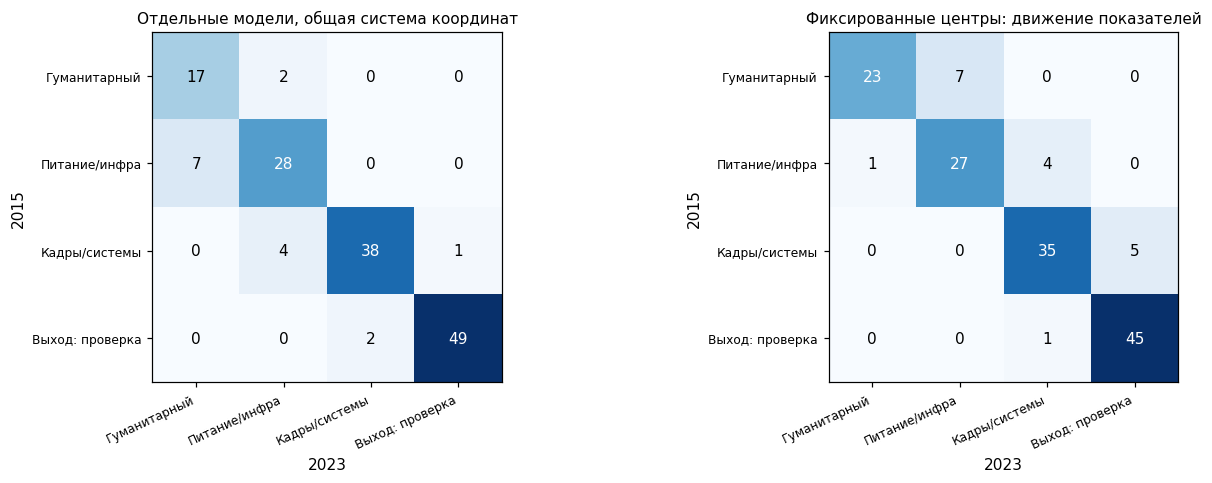

In [27]:
labels2015_fixed = np.array([renumber[g] for g in model.predict(Y2015)])
labels2023_fixed = np.array([renumber[g] for g in model.predict(Y)])
assert np.array_equal(labels2023_fixed, labels)
fixed_transitions = transition_matrix(labels2015_fixed, labels)
improved = labels > labels2015_fixed
worsened = labels < labels2015_fixed
unchanged = labels == labels2015_fixed
assert (improved | worsened | unchanged).all()
assert int(improved.sum() + worsened.sum() + unchanged.sum()) == len(df)

direction = np.select([improved, worsened], ['Поднялись: потребность снизилась',
                                          'Опустились: потребность выросла'], default='Без смены группы')
temporal_country_check = pd.DataFrame({'iso3': df.iso3, 'country': df.country,
    'Группа 2015: отдельная модель': labels2015_refit,
    'Группа 2015: фиксированные границы': labels2015_fixed,
    'Группа 2023': labels, 'Направление по фиксированным границам': direction,
    'Заполнено 2015': R2015.isna().sum(axis=1), 'Заполнено 2023': R.isna().sum(axis=1)})
temporal_ari_fixed = adjusted_rand_score(labels2015_fixed, labels)
direction_comparison = pd.DataFrame([
    ['Отдельная модель 2015, общие масштабы', int(refit_improved.sum()), int(refit_worsened.sum()),
     int(refit_unchanged.sum()), temporal_ari_refit],
    ['Фиксированные центры 2023', int(improved.sum()), int(worsened.sum()),
     int(unchanged.sum()), temporal_ari_fixed]
], columns=['Проверка', 'Поднялись', 'Опустились', 'Без смены группы', 'ARI'])
display(direction_comparison.round(3))
display(fixed_transitions)
display(Markdown(f'**Почему результаты двух сравнений различаются:** отдельное обучение даёт '
    f'{refit_improved.sum()} поднявшихся и {refit_worsened.sum()} опустившихся стран, '
    f'фиксированные границы — {improved.sum()} и {worsened.sum()}. '
    'Средняя потребность сопоставленных центров 2023 года ниже, чем 2015 года: границы относительных групп '
    'сдвинулись вместе с общим развитием стран. Поэтому смена относительной группы может означать '
    'отставание от улучшившихся соседей, даже если собственные показатели стали лучше. '
    'Для распределения пакетов по единой шкале потребности используем фиксированные границы; '
    'отдельные разбиения сохраняем как требуемое сравнение структуры групп.'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
short_names = ['Гуманитарный', 'Питание/инфра', 'Кадры/системы', 'Выход: проверка']
for ax, matrix, title in zip(axes, [refit_transitions, fixed_transitions],
        ['Отдельные модели, общая система координат', 'Фиксированные центры: движение показателей']):
    im = ax.imshow(matrix, cmap='Blues')
    ax.set_xticks(range(K), short_names, rotation=25, ha='right', fontsize=8)
    ax.set_yticks(range(K), short_names, fontsize=8)
    ax.set_xlabel('2023'); ax.set_ylabel('2015'); ax.set_title(title, fontsize=10)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, str(matrix.iloc[i, j]), ha='center', va='center',
                    color='white' if matrix.iloc[i, j] > matrix.to_numpy().max()/2 else 'black')
plt.tight_layout(); plt.show()

### 8.3. Что меняется в распределении пакетов

К одинаковым профилям применяем **одинаковое правило назначения пакетов обоих годов**. Ни доходные ориентиры выхода, ни правило вместимости для 2015 года не подбираем заново. Нагрузка 2015 года — контрфактическая классификация по нынешним правилам фонда, не сведения о фактических исторических программах.

Вывод для распределения ресурсов опирается прежде всего на фиксированные границы. В таблице различаем входящих и выходящих: уменьшение общего размера пакета может скрывать новых нуждающихся. Для каждого пакета лимит 40 проверяется отдельно. Переход на более лёгкую поддержку уменьшает интенсивность помощи, но не всегда освобождает место во всех пакетах.

In [28]:
package_changes = []
for g in range(1, K+1):
    before_mask = labels2015_fixed == g
    after_mask = labels == g
    before_n, after_n = int(before_mask.sum()), int(after_mask.sum())
    entered = int((after_mask & ~before_mask).sum())
    left = int((before_mask & ~after_mask).sum())
    limit = CAPACITY if actions[g] != 'Рассмотрение выхода' else np.nan
    package_changes.append([group_names[g], actions[g], before_n, after_n, after_n-before_n,
                            entered, left, limit, limit-after_n])
temporal_packages = pd.DataFrame(package_changes, columns=['Профиль', 'Решение', 'Стран 2015',
    'Стран 2023', 'Изменение', 'Вошли', 'Вышли', 'Лимит', 'Запас мест 2023'])
assert temporal_packages['Стран 2015'].sum() == temporal_packages['Стран 2023'].sum() == len(df)
assert (temporal_packages['Вошли'] - temporal_packages['Вышли']).equals(temporal_packages['Изменение'])
display(temporal_packages)
assert temporal_packages.loc[temporal_packages['Лимит'].notna(), 'Стран 2023'].le(CAPACITY).all()

transition_flows = []
for old in range(1, K+1):
    for new in range(1, K+1):
        if old == new or not fixed_transitions.loc[old, new]:
            continue
        transition_flows.append([actions[old], actions[new], int(fixed_transitions.loc[old, new]),
                                 'Поднялись' if new > old else 'Опустились'])
display(pd.DataFrame(transition_flows, columns=['Решение 2015', 'Решение 2023', 'Стран', 'Направление']))

# Проверяем, сопровождается ли переход движением реальных индикаторов.
changes = pd.DataFrame({'Направление': direction,
    'Δ смертности до 5 лет /1000': filled.under5_mortality_per_1000 - filled2015.under5_mortality_per_1000,
    'Δ DTP3, п.п.': filled.immunization_dtp3_pct - filled2015.immunization_dtp3_pct,
    'Δ низкорослости, п.п.': filled.stunting_under5_pct - filled2015.stunting_under5_pct,
    'Δ санитарии, п.п.': filled.access_sanitation_pct - filled2015.access_sanitation_pct,
    'Δ общей потребности, z': X.mean(axis=1) - X2015.mean(axis=1)})
print('Медианные изменения показателей по направлениям:')
display(changes.groupby('Направление').median().round(2))
new_exit_candidates = (labels2015_fixed < K) & (labels == K)
new_exit_failed = new_exit_candidates & ~individual_exit
print('Новых кандидатов на рассмотрение выхода:', int(new_exit_candidates.sum()),
      '; из них не проходят индивидуальные ориентиры:', int(new_exit_failed.sum()))
print('Денежную экономию не рассчитываем: стоимость пакетов и программ в данных отсутствует.')

,Профиль,Решение,Стран 2015,Стран 2023,Изменение,Вошли,Вышли,Лимит,Запас мест 2023
0,Острые дефициты здоровья и базовых условий,Гуманитарный режим,30,24,-6,1,7,40.0,16.0
1,Высокая потребность в питании и инфраструктуре,Инфраструктура и питание,32,34,2,7,5,40.0,6.0
2,Остаточные дефициты медицинских ресурсов и систем,Кадры и системы,40,40,0,5,5,40.0,0.0
3,Низкая общая потребность с индивидуальными иск...,Рассмотрение выхода,46,50,4,5,1,NaN,NaN


,Решение 2015,Решение 2023,Стран,Направление
0,Гуманитарный режим,Инфраструктура и питание,7,Поднялись
1,Инфраструктура и питание,Гуманитарный режим,1,Опустились
2,Инфраструктура и питание,Кадры и системы,4,Поднялись
3,Кадры и системы,Рассмотрение выхода,5,Поднялись
4,Рассмотрение выхода,Кадры и системы,1,Опустились


Медианные изменения показателей по направлениям:


,Δ смертности до 5 лет /1000,"Δ DTP3, п.п.","Δ низкорослости, п.п.","Δ санитарии, п.п.","Δ общей потребности, z"
Направление,,,,,
Без смены группы,-2.65,-1.0,-0.29,2.30,-0.07
Опустились: потребность выросла,-1.20,-35.0,0.22,10.90,0.32
Поднялись: потребность снизилась,-7.70,1.0,-2.65,7.25,-0.26


Новых кандидатов на рассмотрение выхода: 5 ; из них не проходят индивидуальные ориентиры: 3
Денежную экономию не рассчитываем: стоимость пакетов и программ в данных отсутствует.


### 8.4. Неопределённость динамики и короткий вывод для фонда

USD в двух годах не скорректированы на инфляцию и PPP; рост номинального ВВП нельзя целиком считать реальным прогрессом. Измерения обследований могут отставать от среза до пяти лет, а пропуски в двух годах различаются. Поэтому ниже отделяем переходы, согласующиеся в двух схемах, от зависимых от перемещения границ, и проверяем влияние случайного донорного заполнения с теми же фиксированными шкалами и центрами.

Это проверка чувствительности, не доверительный интервал и не прогноз 2023 → следующий год. Переход в группу выхода сам по себе не разрешает прекращать программы.

In [29]:
refit_direction_code = np.sign(labels - labels2015_refit)
fixed_direction_code = np.sign(labels - labels2015_fixed)
direction_agreement = refit_direction_code == fixed_direction_code
print('Направление совпадает у', int(direction_agreement.sum()), 'из', len(df), 'стран.')
print('Поднялись в обеих схемах:', int((refit_improved & improved).sum()),
      '; опустились в обеих схемах:', int((refit_worsened & worsened).sum()))

temporal_donor_counts = []
for repeat in range(30):
    draw15 = impute_data(R2015, parameters=imputation_parameters, rng=np.random.default_rng(2000+repeat))
    draw23 = impute_data(R, parameters=imputation_parameters, rng=np.random.default_rng(3000+repeat))
    y15 = pca.transform(transform_with_reference(draw15))[:, :n_components]
    y23 = pca.transform(transform_with_reference(draw23))[:, :n_components]
    l15 = np.array([renumber[g] for g in model.predict(y15)])
    l23 = np.array([renumber[g] for g in model.predict(y23)])
    temporal_donor_counts.append([(l23 > l15).sum(), (l23 < l15).sum(), (l23 == l15).sum()])
temporal_donor_counts = np.array(temporal_donor_counts)
display(pd.DataFrame(np.quantile(temporal_donor_counts, [.1, .5, .9], axis=0).T,
    index=['Поднялись', 'Опустились', 'Без смены группы'], columns=['p10 сценариев', 'Медиана', 'p90 сценариев']))

humanitarian_change = temporal_packages.loc[temporal_packages.Решение.eq('Гуманитарный режим')].iloc[0]
nutrition_change = temporal_packages.loc[temporal_packages.Решение.eq('Инфраструктура и питание')].iloc[0]
if worsened.any():
    worsening_advice = (f'{int(worsened.sum())} странам с переходом к большей потребности дать приоритетную усиленную помощь '
        'после сверки актуальных данных, сохраняя лимит 40 стран на пакет')
else:
    worsening_advice = ('переходов к большей потребности не выявлено; резерв сохранить для подтверждённых локальных ухудшений')
bonus_conclusion = (f'После проверки улучшений у {int(improved.sum())} поднявшихся стран перераспределить '
    f'высвобождающийся ресурс гуманитарного режима '
    f'({int(humanitarian_change["Стран 2015"])}→{int(humanitarian_change["Стран 2023"])} стран) '
    f'на расширение пакета питания '
    f'({int(nutrition_change["Стран 2015"])}→{int(nutrition_change["Стран 2023"])}), '
    'углубление работы в уже охваченных 40 странах системного пакета и резерв, без автоматического выхода из программ. '
    + worsening_advice[0].upper() + worsening_advice[1:] + '; денежную экономию по этому датасету оценить нельзя.')
display(Markdown('**Вывод для фонда (две фразы):** ' + bonus_conclusion))

Направление совпадает у 124 из 148 стран.
Поднялись в обеих схемах: 3 ; опустились в обеих схемах: 2


,p10 сценариев,Медиана,p90 сценариев
Поднялись,14.9,17.0,19.0
Опустились,1.9,2.5,4.0
Без смены группы,126.9,129.0,131.0


**Вывод для фонда (две фразы):** После проверки улучшений у 16 поднявшихся стран перераспределить высвобождающийся ресурс гуманитарного режима (30→24 стран) на расширение пакета питания (32→34), углубление работы в уже охваченных 40 странах системного пакета и резерв, без автоматического выхода из программ. 2 странам с переходом к большей потребности дать приоритетную усиленную помощь после сверки актуальных данных, сохраняя лимит 40 стран на пакет; денежную экономию по этому датасету оценить нельзя.

### Ограничения и воспроизводимость

* K-means предполагает компактные группы по евклидовым расстояниям. Потребность может быть непрерывной; высокий silhouette при двух группах не доказывает существование двух естественных типов стран.
* Результат зависит от признаков, логарифмов, равных весов блоков и допущений о пропусках. Таблица чувствительности показывает эту зависимость числами; ARI = 1 означает совпадение разбиений, близкий к 0 — слабое согласие относительно случайной точки отсчёта.
* Даты отдельных измерений отсутствуют, а некоторые обследования могут отставать на пять лет; нельзя считать все наблюдения строго одновременными.
* Основные результаты относятся к 2023 году; пункт 8 сравнивает срезы 2015→2023 с общими параметрами подготовки, масштабирования и PCA.
* При добавлении новых стран нужно применять сохранённые правила подготовки/масштабирования и PCA, либо переобучать весь анализ и снова проверять вместимость пакетов; нельзя смешивать старые и новые масштабы.

за эту лабу


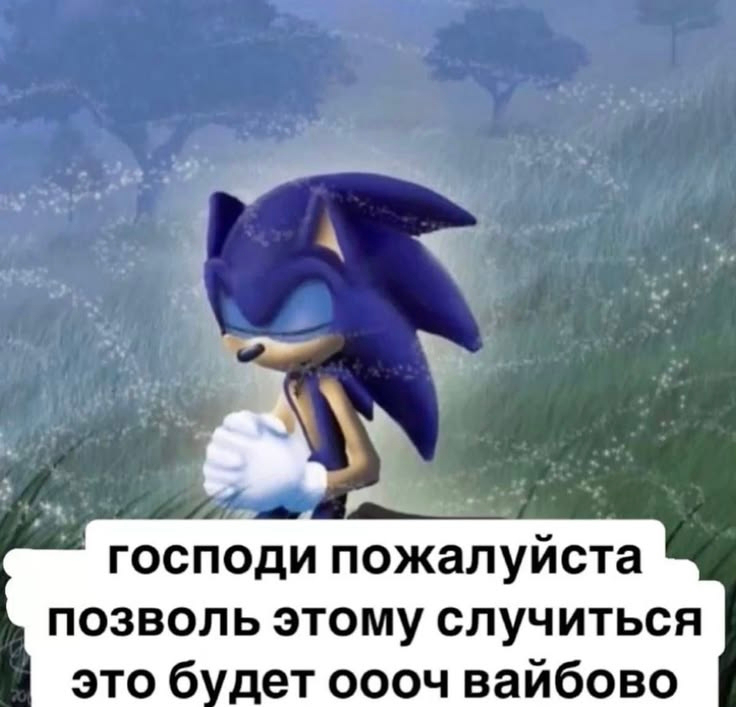

In [30]:
# Картинки вернулись и за прошлый раз, и бонус
from PIL import Image
img = Image.open("Vaib.jpg")
print("за эту лабу")
img

за прошлую лабу


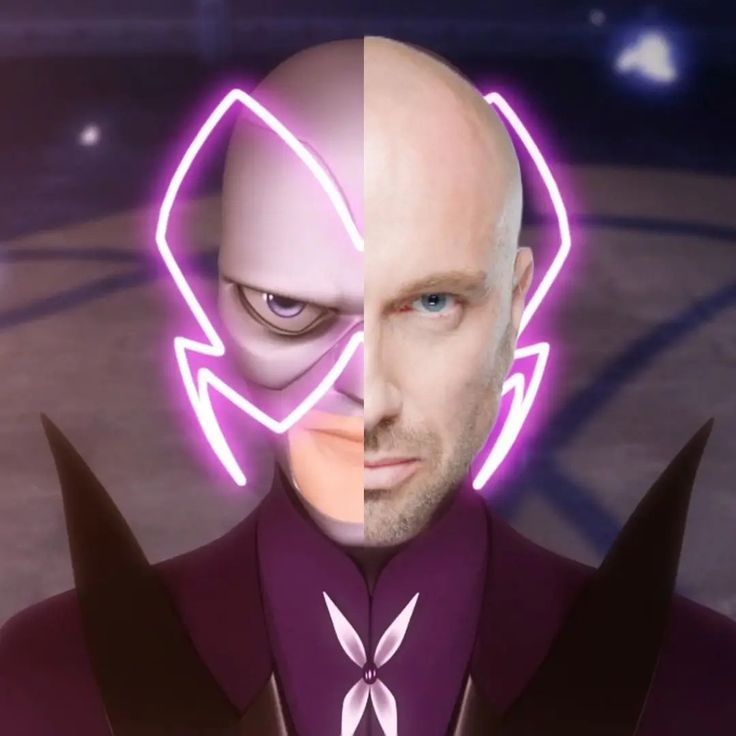

In [31]:
img = Image.open("style.jpg")
print("за прошлую лабу")
img

бонус за то что сmogg сделать во время


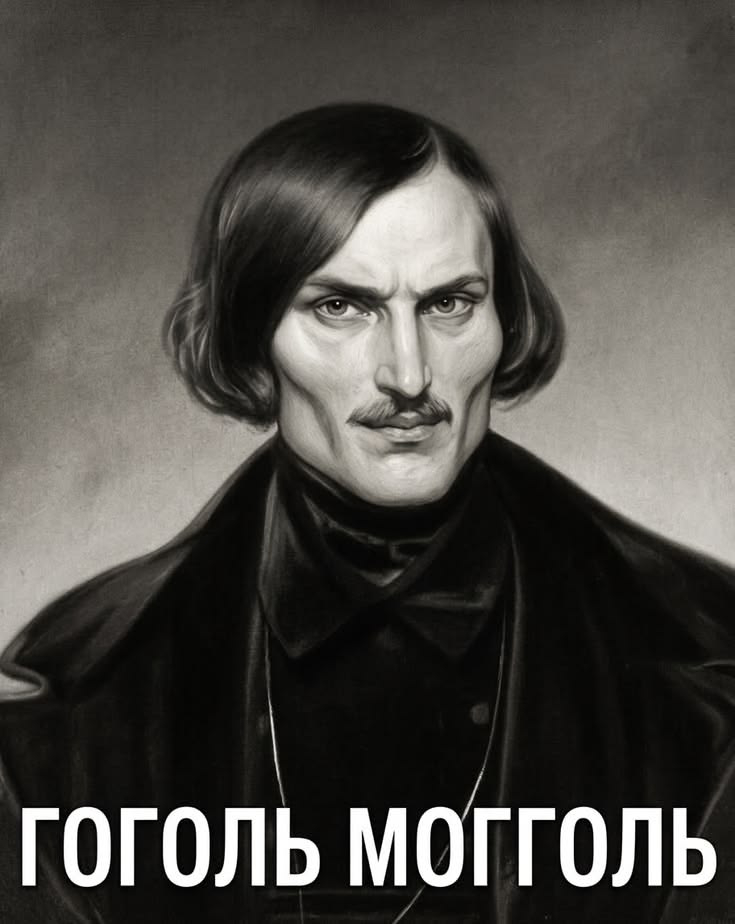

In [32]:
img = Image.open("moggol.jpg")
print("бонус за то что сmogg сделать во время")
img